# Bài tập lớn Học máy — Bài 1: Dữ liệu dạng bảng
## Dự đoán khách hàng rời bỏ (Customer Churn) — Telecom Customer Churn

**Môn học:** Học máy (Machine Learning) · Học kỳ I, 2026–2027 · Khoa KH&KT Máy tính, ĐH Bách Khoa – ĐHQG-HCM

| | |
|---|---|
| Bài toán | Phân loại nhị phân: khách hàng có rời bỏ nhà mạng (`churn = 1`) hay không |
| Dữ liệu | Telecom Customer Churn (nguồn gốc: Teradata Center for CRM, Duke University) — 100.000 khách hàng × 100 cột |
| Pipeline | EDA → Làm sạch → Imputation → Encoding → (Log) + Scaling → PCA → Mô hình → Đánh giá |
| Mô hình | Mốc Dummy (đoán theo tỷ lệ lớp), Logistic Regression, Linear SVM, k-NN, Naive Bayes, Random Forest, Gradient Boosting, LightGBM; mở rộng: MLP (sklearn, PyTorch) |

Mọi logic nằm trong package `modules/` (notebook chỉ gọi hàm và hiển thị). Toàn bộ kết quả của notebook
cũng tái tạo được bằng một lệnh: `uv run churn --config configs/default.yaml`.

**Mục lục**
0. Cài đặt môi trường & tải dữ liệu
1. EDA (Exploratory Data Analysis)
2. Tiền xử lý & pipeline cấu hình được
3. Thí nghiệm so sánh cấu hình (cross-validation trên tập train)
4. Tinh chỉnh siêu tham số
5. Đánh giá cuối cùng trên tập test
6. Lưu đặc trưng (`features/*.npy`)
7. Mở rộng: Deep Learning (MLP) so với pipeline truyền thống
8. Kết luận

> **Nguyên tắc đánh giá:** mọi lựa chọn cấu hình chỉ dựa trên **cross-validation trên tập train**.
> Tập test (20%) được giữ riêng và chỉ dùng **một lần** ở mục 5 để báo cáo kết quả cuối cùng.

## 0. Cài đặt môi trường & tải dữ liệu

In [1]:
# Chạy trên Google Colab (Runtime -> Run all) hoặc máy cá nhân. KHÔNG mount Google Drive.
# Colab: mã nguồn (package modules/) được clone từ GitHub; thư viện thiếu được cài tự động.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/Kunneaa/Churn-Prediction.git"  # repo public của nhóm
REPO_DIR = Path("Churn-Prediction")

if Path("modules").is_dir():
    pass  # đang ở gốc repo
elif Path("../modules").is_dir():
    os.chdir("..")  # chạy từ notebooks/
else:  # Colab
    if not REPO_DIR.is_dir():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True)
    os.chdir(REPO_DIR)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True
    )
sys.path.insert(0, str(Path.cwd()))
print("Thư mục làm việc:", Path.cwd())

Thư mục làm việc: /Users/kunne/Downloads/ML


In [2]:
import time

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display

from modules import reporting
from modules.app import configure_runtime
from modules.datasets import ID_COLUMN, TARGET, download_data, load_raw
from modules.evaluation import summary_table
from modules.experiments import (
    baseline_config,
    best_by_cv,
    encoding_stage,
    error_analysis,
    export_stage,
    final_stage,
    importance,
    imputation_stage,
    load_experiment_settings,
    mlp_stage,
    model_stage,
    pca_explained_variance,
    pca_stage,
    save_table,
    scaling_stage,
    selection_stage,
    significance_stage,
    tuning_stage,
)
from modules.featurize import load_features
from modules.modeling import BASELINE, build_pipeline, build_preprocessing
from modules.preprocessing import clean, load_dataset, subsample_train
from modules.shared import get_settings

configure_runtime()  # logging + bỏ cảnh báo đã xử lý theo thiết kế
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
SETTINGS = get_settings()
S = load_experiment_settings(SETTINGS.experiment_config)  # configs/default.yaml
NOTEBOOK_T0 = time.time()
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "|", S)

scikit-learn 1.9.1 | pandas 3.1.1 | ExperimentSettings(seed=42, test_size=0.2, cv=3, cv_repeats=3, stage_sample=30000, threshold_cv=3, threshold_sample=30000, importance_sample=5000, tuning=TuningSettings(sample=20000, cv=3, n_iter={'logreg': 5, 'random_forest': 5, 'hist_gb': 5}, spaces={'logreg': {'model__C': [0.001, 0.01, 0.1, 1, 10]}, 'random_forest': {'model__n_estimators': [150, 300], 'model__max_depth': [10, 14, 20], 'model__min_samples_leaf': [5, 10, 20, 50], 'model__max_features': ['sqrt', 0.3, 0.5]}, 'hist_gb': {'model__learning_rate': [0.03, 0.05, 0.1], 'model__max_leaf_nodes': [15, 31, 63], 'model__min_samples_leaf': [20, 50, 100], 'model__l2_regularization': [0.0, 1.0, 5.0]}}, fixed=['lightgbm']), mlp=[{'hidden_layer_sizes': [64], 'alpha': 0.001}, {'hidden_layer_sizes': [128, 64], 'alpha': 0.001}, {'hidden_layer_sizes': [128, 64], 'alpha': 0.01}, {'hidden_layer_sizes': [256, 128, 64], 'alpha': 0.01}, {'model': 'torch_mlp', 'hidden_layer_sizes': [128, 64], 'dropout': 0.2}, {

In [3]:
# Dữ liệu tải từ nguồn công khai (Kaggle public endpoint, không cần tài khoản), giải nén vào data/raw/
print("Trang dataset:", SETTINGS.dataset_page)
print("Link tải     :", SETTINGS.data_url)
download_data()
raw = load_raw()
print("Kích thước:", raw.shape)
raw.head()

2026-11-25 10:13:44,665 INFO     modules.datasets.loader: Dữ liệu đã có: /Users/kunne/Downloads/ML/data/raw/Telecom_customer churn.csv


Trang dataset: https://www.kaggle.com/datasets/abhinav89/telecom-customer
Link tải     : https://www.kaggle.com/api/v1/datasets/download/abhinav89/telecom-customer


Kích thước: (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,...,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,Customer_ID
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,...,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0,1000001
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,...,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0,1000002
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,...,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0,1000003
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,...,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0,1000004
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,...,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0,1000005


## 1. EDA (Exploratory Data Analysis)
### 1.1 Tổng quan các cột

In [4]:
ov = reporting.overview(raw)
n_cat = raw.select_dtypes(exclude="number").shape[1]  # đúng cả pandas 2 (object) lẫn 3 (str)
print(
    f"{raw.shape[0]:,} dòng × {raw.shape[1]} cột | {raw.shape[1] - n_cat} cột số, {n_cat} cột phân loại | "
    f"trùng lặp: {raw.duplicated().sum()} | {ID_COLUMN} duy nhất: {raw[ID_COLUMN].is_unique}"
)
display(ov)

100,000 dòng × 100 cột | 79 cột số, 21 cột phân loại | trùng lặp: 0 | Customer_ID duy nhất: True


,dtype,n_unique,n_missing,pct_missing,example
rev_Mean,float64,37468,357,0.36,23.9975
mou_Mean,float64,9730,357,0.36,219.25
totmrc_Mean,float64,8491,357,0.36,22.5
da_Mean,float64,172,357,0.36,0.2475
ovrmou_Mean,float64,2638,357,0.36,0.0
...,...,...,...,...,...
kid11_15,str,2,1732,1.73,U
kid16_17,str,2,1732,1.73,U
creditcd,str,2,1732,1.73,Y
eqpdays,float64,1555,1,0.00,361.0


In [5]:
display(raw.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
rev_Mean,99643.0,58.72,46.29,-6.17,33.26,48.20,70.75,3843.26
mou_Mean,99643.0,513.56,525.17,0.00,150.75,355.50,703.00,12206.75
totmrc_Mean,99643.0,46.18,23.62,-26.92,30.00,44.99,59.99,409.99
da_Mean,99643.0,0.89,2.18,0.00,0.00,0.25,0.99,159.39
ovrmou_Mean,99643.0,41.07,97.30,0.00,0.00,2.75,42.00,4320.75
...,...,...,...,...,...,...,...,...
income,74564.0,5.78,2.18,1.00,4.00,6.00,7.00,9.00
numbcars,50634.0,1.57,0.63,1.00,1.00,1.00,2.00,3.00
forgntvl,98268.0,0.06,0.23,0.00,0.00,0.00,0.00,1.00
eqpdays,99999.0,391.93,256.48,-5.00,212.00,342.00,530.00,1823.00


### 1.2 Phân phối nhãn

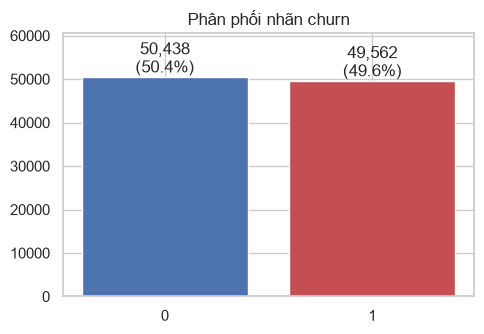

In [6]:
reporting.plot_target(raw[TARGET], save="01_target_distribution")
plt.show()

### 1.3 Giá trị thiếu
Dữ liệu có ba loại giá trị thiếu:
1. **Thiếu tường minh** (`NaN`) — chủ yếu ở các cột nhân khẩu học (`numbcars`, `dwllsize`, `HHstatin`, `ownrent`, `income`, …).
2. **Thiếu ẩn**: mã `"U"` (unknown) trong `new_cell`, `marital`, `ethnic`, `dualband`; `"UNKW"` trong `hnd_webcap`;
   `eqpdays < 0` (số ngày sử dụng thiết bị không thể âm).
   *Lưu ý:* `"U"` trong `prizm_social_one` nghĩa là **Urban** (thành thị), **không phải** giá trị thiếu.
3. **Thiếu có cấu trúc**: `avg6mou`, `avg6qty`, `avg6rev` (trung bình 6 tháng) thiếu với khách hàng mới chỉ có 6 tháng.

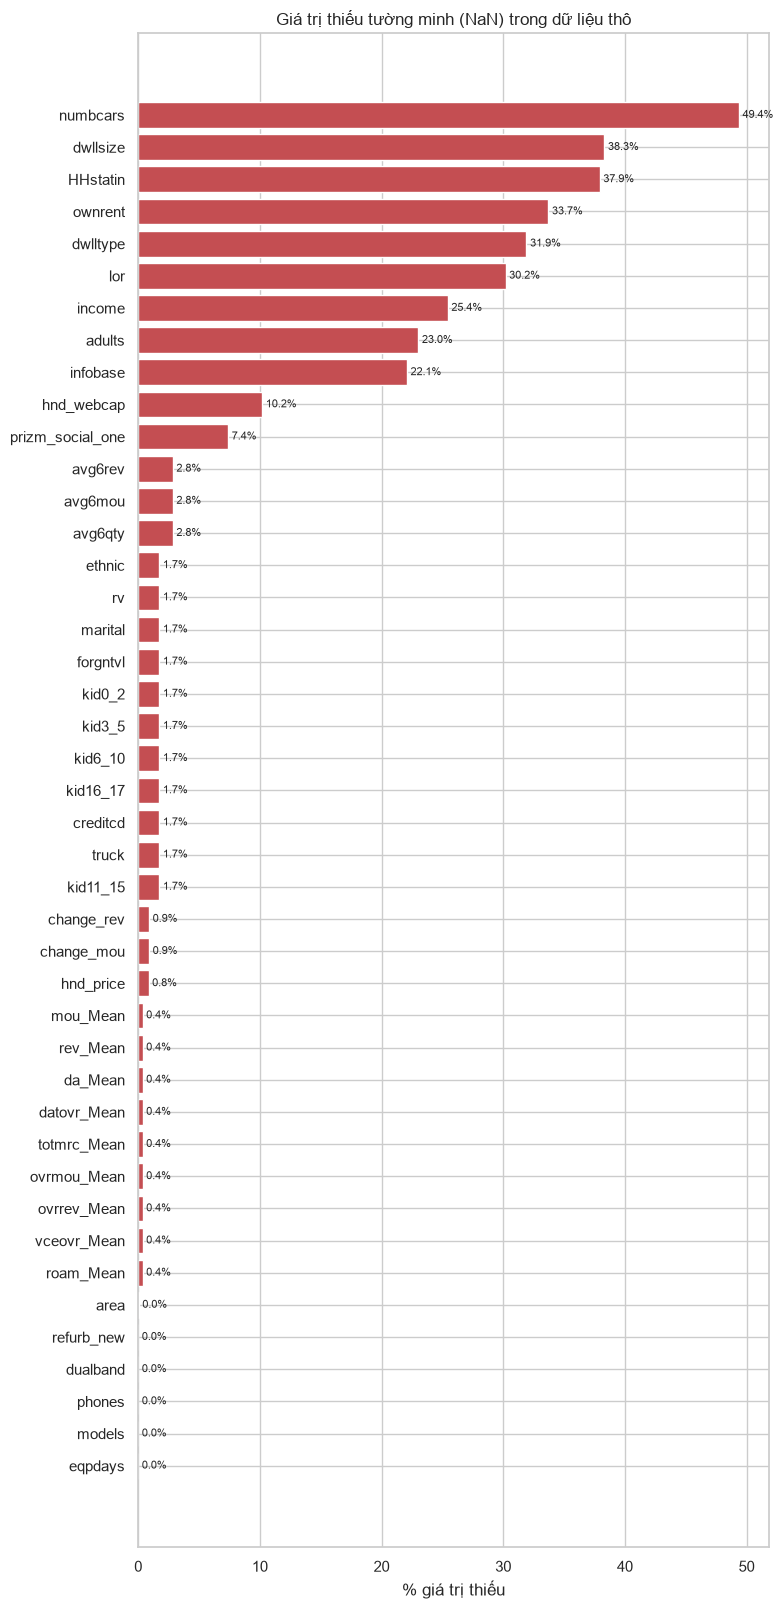

Giá trị thiếu ẩn:


,cột,giá trị,số dòng,% dữ liệu,churn rate khi thiếu (%),churn rate còn lại (%)
0,new_cell,U,66914,66.91,49.70,49.29
3,marital,U,37333,37.33,51.27,48.55
4,ethnic,U,10945,10.94,50.02,49.51
2,hnd_webcap,UNKW,235,0.24,36.60,49.59
1,dualband,U,222,0.22,34.68,49.60
5,eqpdays,"-1.0, -2.0, -3.0",133,0.13,35.34,49.58


In [7]:
reporting.plot_missing(
    raw, "Giá trị thiếu tường minh (NaN) trong dữ liệu thô", save="02_missing_raw"
)
plt.show()
print("Giá trị thiếu ẩn:")
display(reporting.hidden_missing_report(raw))

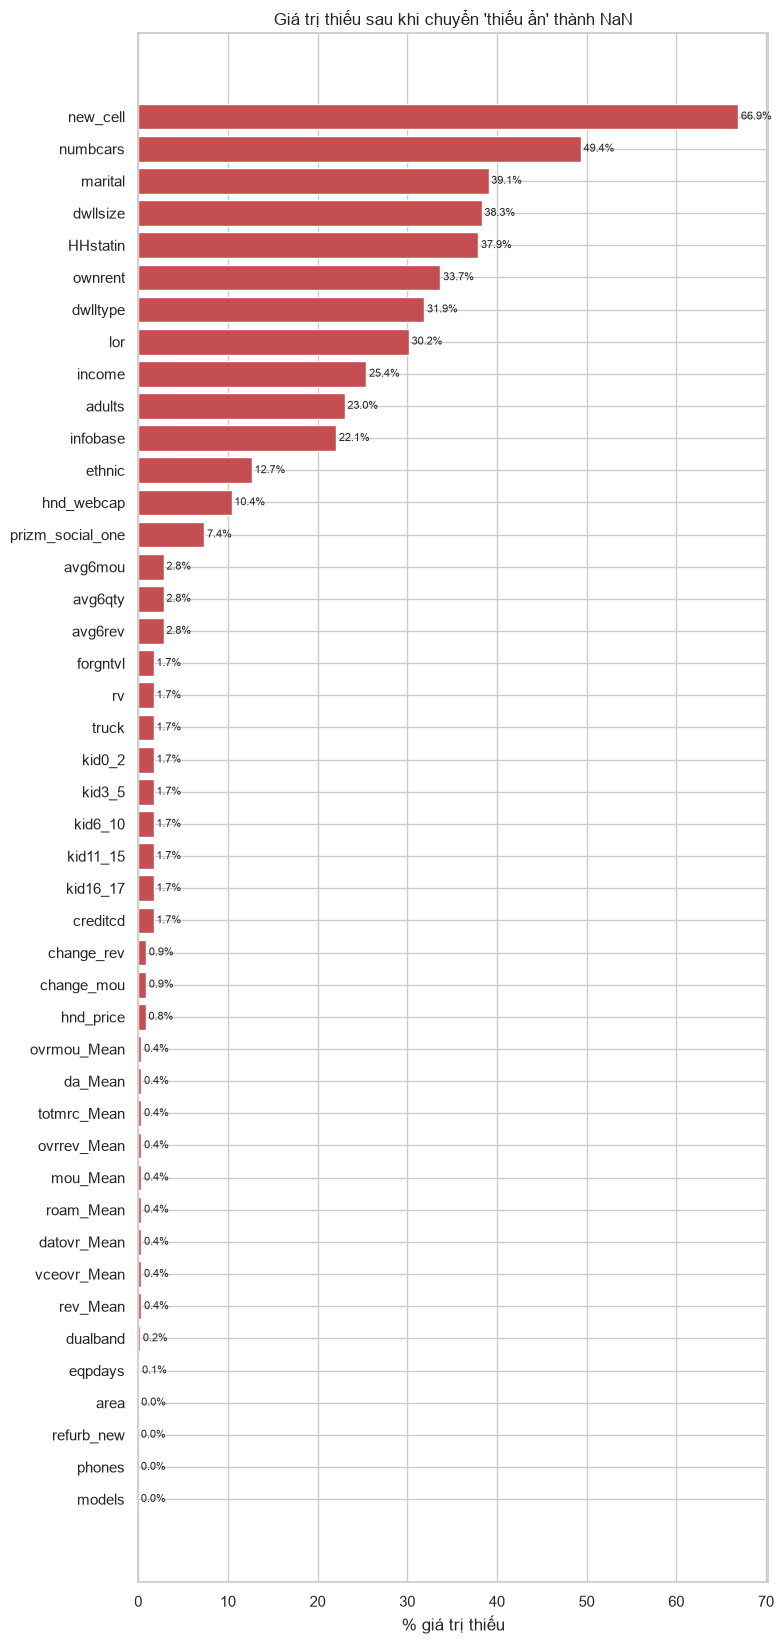

Tỷ lệ dòng có ít nhất 1 giá trị thiếu: thô = 73.3%, sau khi xử lý thiếu ẩn = 93.0%


In [8]:
cleaned = clean(raw, treat_hidden_missing=True)
reporting.plot_missing(
    cleaned, "Giá trị thiếu sau khi chuyển 'thiếu ẩn' thành NaN", save="03_missing_after_clean"
)
plt.show()
print(
    f"Tỷ lệ dòng có ít nhất 1 giá trị thiếu: thô = {raw.isna().any(axis=1).mean():.1%}, "
    f"sau khi xử lý thiếu ẩn = {cleaned.isna().any(axis=1).mean():.1%}"
)

In [9]:
# Giá trị thiếu có mang thông tin về churn không? (có -> nên thêm cờ "is_missing")
display(reporting.missing_vs_churn(cleaned, top=20))
print("Tỷ lệ thiếu avg6mou theo số tháng sử dụng (months):")
display(reporting.missing_by_months(raw))

,cột,% thiếu,churn khi thiếu (%),churn khi có (%),chênh lệch
11,new_cell,66.91,49.7,49.3,0.4
32,numbcars,49.37,50.2,48.9,1.3
28,marital,39.06,51.1,48.6,2.5
34,dwllsize,38.31,51.0,48.6,2.4
33,HHstatin,37.92,51.0,48.7,2.3
25,ownrent,33.71,51.0,48.8,2.2
27,dwlltype,31.91,51.2,48.8,2.4
26,lor,30.19,51.4,48.8,2.6
31,income,25.44,51.4,48.9,2.5
29,adults,23.02,51.7,48.9,2.8


Tỷ lệ thiếu avg6mou theo số tháng sử dụng (months):


months,6,7,8,9,10,11,12
% thiếu,100.0,26.1,0.9,0.4,0.2,0.3,0.2


**Nhận xét (giá trị thiếu).** Tỷ lệ dòng có ít nhất một giá trị thiếu tăng từ **73,3%** (chỉ tính NaN) lên **93,0%** sau khi đổi thiếu ẩn thành `NaN` — không thể bỏ dòng thiếu, bắt buộc phải impute.
Hai loại thiếu **mang thông tin về churn**: khách hàng thiếu `hnd_webcap` churn **58,6%** (so với 48,5%), còn khách hàng
thiếu `avg6*` (mới dùng đúng 6 tháng — thiếu có cấu trúc, 100% ở `months = 6`) churn chỉ **40,2%**. Các cột nhân khẩu học
(`numbcars`, `dwllsize`, `income`, …) thiếu 23–49% nhưng chênh lệch churn chỉ 2–3 điểm %. ⇒ Dùng imputation **kèm cờ
thiếu** (`add_missing_indicator`) để mô hình học được chính việc "bị thiếu"; kiểm chứng ở 3.1.

### 1.4 Biến số: phân phối, độ lệch và ngoại lai

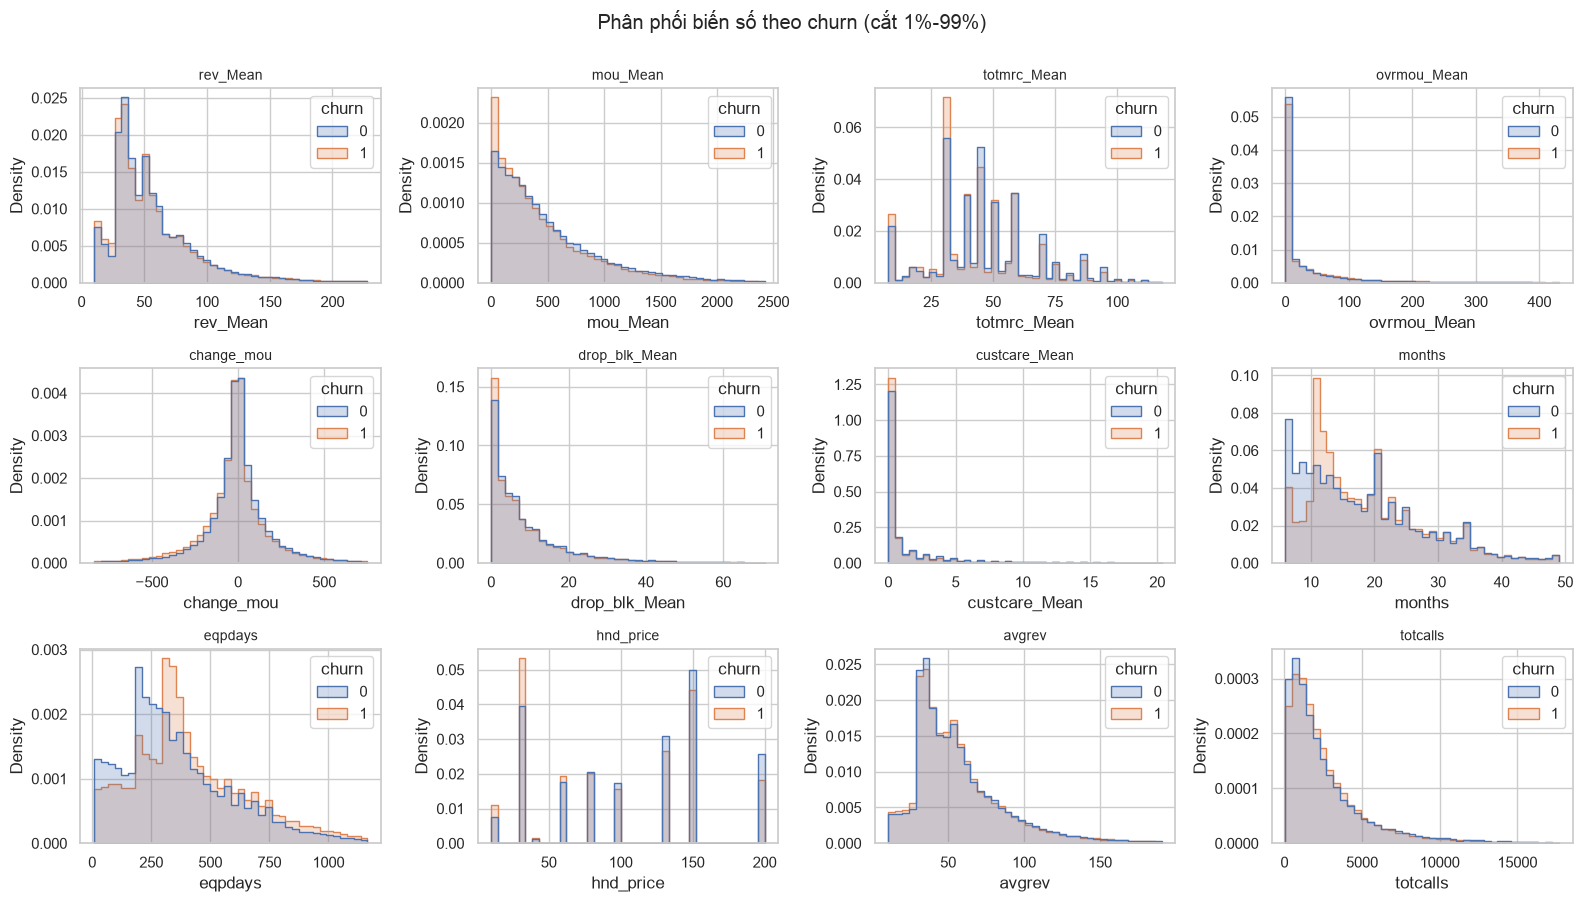

In [10]:
KEY_NUMERIC = [
    "rev_Mean",
    "mou_Mean",
    "totmrc_Mean",
    "ovrmou_Mean",
    "change_mou",
    "drop_blk_Mean",
    "custcare_Mean",
    "months",
    "eqpdays",
    "hnd_price",
    "avgrev",
    "totcalls",
]
reporting.plot_numeric_distributions(raw, KEY_NUMERIC, save="04_numeric_distributions")
plt.show()

,cột,min,Q1,median,Q3,max,skew,n_outliers,% outliers
10,change_rev,-1107.74,-7.36,-0.32,1.64,9963.66,80.54,25816,26.05
8,roam_Mean,0.00,0.00,0.00,0.24,3685.20,168.81,18914,18.98
69,truck,0.00,0.00,0.00,0.00,1.00,1.59,18555,18.88
18,plcd_dat_Mean,0.00,0.00,0.00,0.00,733.67,30.27,14980,14.98
47,callwait_Mean,0.00,0.00,0.33,1.33,212.67,11.14,14305,14.31
25,cc_mou_Mean,0.00,0.00,0.00,2.87,602.95,10.57,14265,14.26
7,datovr_Mean,0.00,0.00,0.00,0.00,423.54,58.01,13673,13.72
9,change_mou,-3875.00,-87.00,-6.25,63.00,31219.25,14.39,13490,13.61
24,ccrndmou_Mean,0.00,0.00,0.00,4.00,861.33,11.57,13456,13.46
22,comp_dat_Mean,0.00,0.00,0.00,0.00,559.33,28.64,13393,13.39


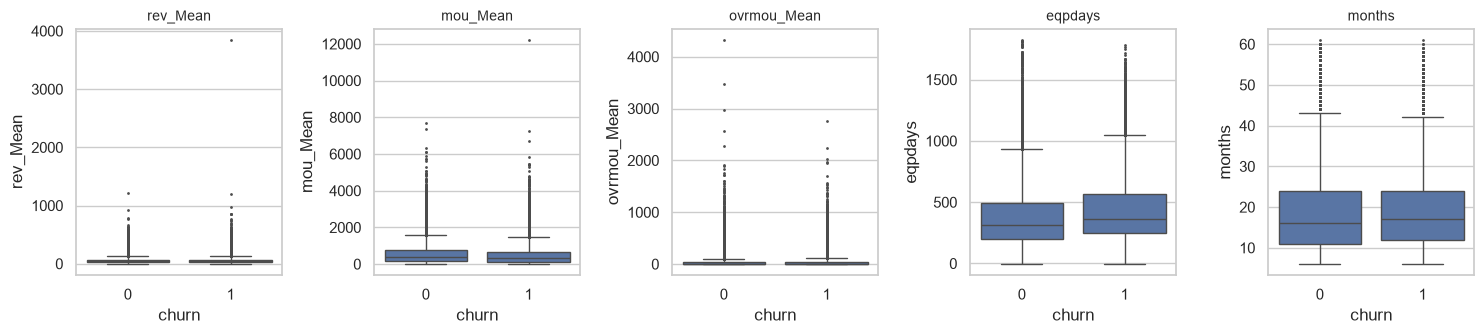

In [11]:
num_cols = raw.select_dtypes("number").columns.drop([ID_COLUMN, TARGET]).tolist()
display(reporting.outlier_table(raw, num_cols).head(15).round(2))
reporting.plot_boxplots(
    raw, ["rev_Mean", "mou_Mean", "ovrmou_Mean", "eqpdays", "months"], save="05_boxplots"
)
plt.show()

**Nhận xét (biến số).** Các biến sử dụng/cước lệch phải rất mạnh (skew của `change_rev` 80, `roam_Mean` 169) và có
10–26% ngoại lai theo IQR. Ngoại lai ở đây là hành vi thật (khách dùng nhiều) chứ không phải lỗi nhập, nên **không xoá**
mà giảm ảnh hưởng bằng biến đổi `log1p` giữ dấu (thử ở 3.3) hoặc dùng mô hình cây (không nhạy với thang đo).

### 1.5 Biến phân loại và tỷ lệ churn theo nhóm

,n_unique,giá trị phổ biến nhất
crclscod,54,AA
area,19,NEW YORK CITY AREA
ethnic,17,N
dwllsize,15,A
HHstatin,6,C
marital,5,U
prizm_social_one,5,S
dualband,4,Y
new_cell,3,U
hnd_webcap,3,WCMB


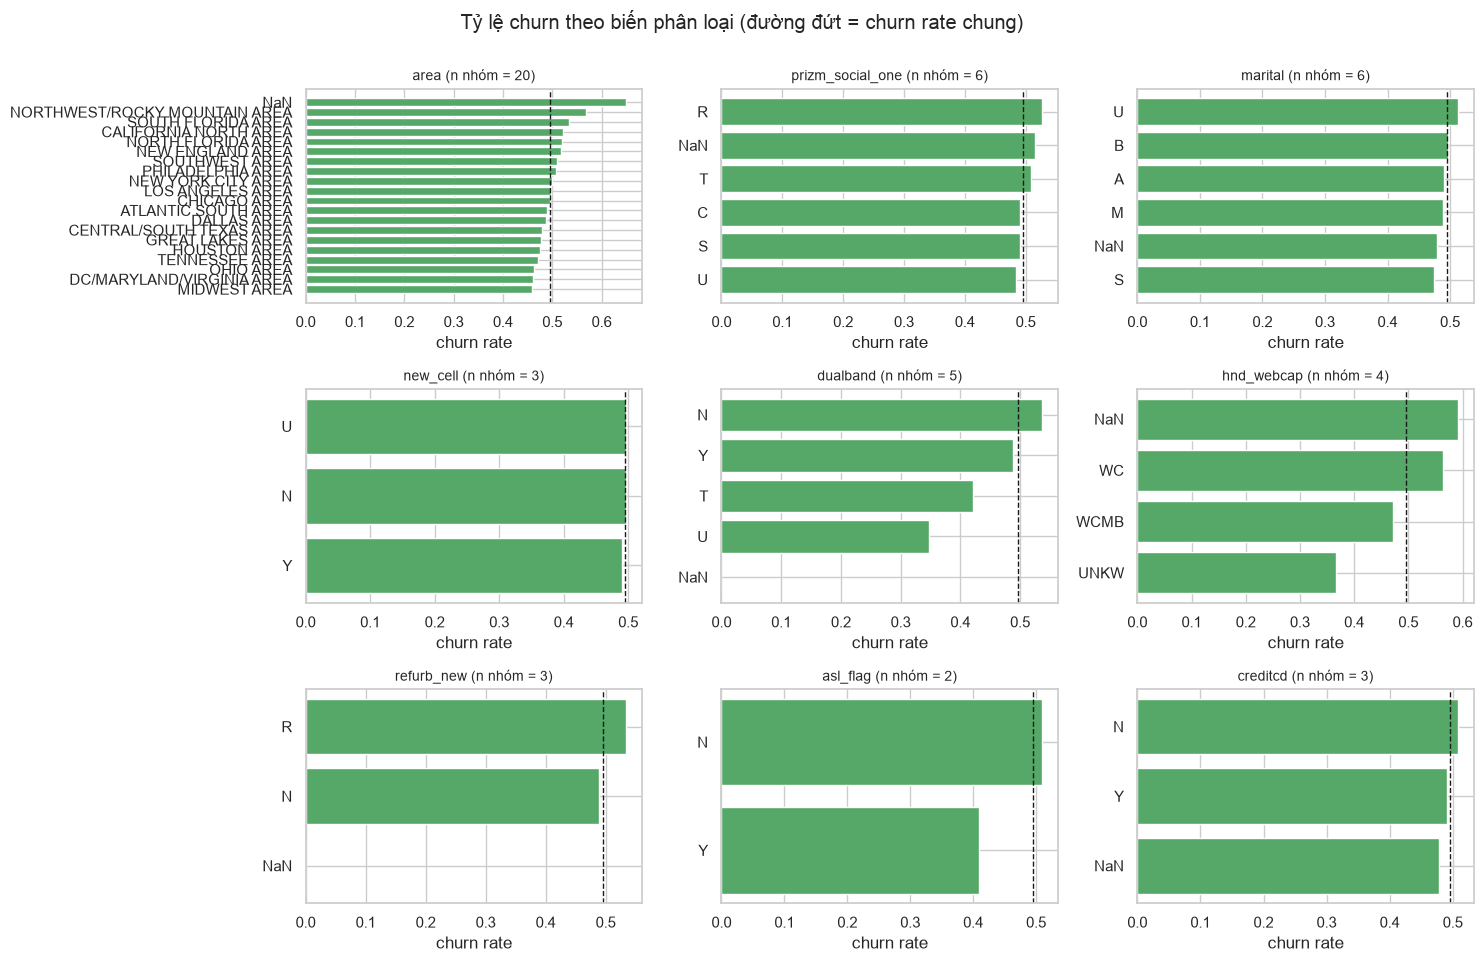

In [12]:
display(reporting.category_summary(raw))
reporting.plot_churn_rate_by_category(
    raw,
    [
        "area",
        "prizm_social_one",
        "marital",
        "new_cell",
        "dualband",
        "hnd_webcap",
        "refurb_new",
        "asl_flag",
        "creditcd",
    ],
    save="06_churn_by_category",
)
plt.show()

crclscod: 54 giá trị | 13 mã có < 20 khách hàng | churn rate giữa các mã (n>=500): 0.31 – 0.62


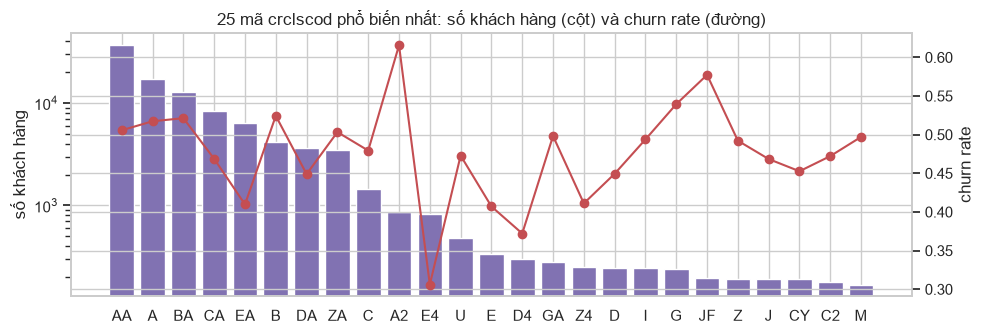

In [13]:
# crclscod (credit class code): 54 giá trị, nhiều mã rất hiếm -> cần encoding cho cột nhiều giá trị
cc = reporting.category_churn(raw, "crclscod")
big = cc[cc.n >= 500]
print(
    f"crclscod: {len(cc)} giá trị | {(cc.n < 20).sum()} mã có < 20 khách hàng | "
    f"churn rate giữa các mã (n>=500): {big.churn_rate.min():.2f} – {big.churn_rate.max():.2f}"
)
reporting.plot_category_volume(
    cc.head(25),
    "25 mã crclscod phổ biến nhất: số khách hàng (cột) và churn rate (đường)",
    save="07_crclscod",
)
plt.show()

**Nhận xét (biến phân loại).** `crclscod` có 54 mã, 13 mã có dưới 20 khách hàng, churn rate giữa các mã phổ biến dao động
**31%–62%** ⇒ cột có thông tin nhưng one-hot sẽ sinh nhiều cột hiếm: so sánh frequency / target / one-hot (gộp mã hiếm) /
bỏ cột ở 3.2. Mã `"U"` trong `prizm_social_one` là *Urban*, khác với `"U"` = unknown ở `marital`, `new_cell` — phải đọc
data dictionary trước khi coi là giá trị thiếu.

### 1.6 Tương quan

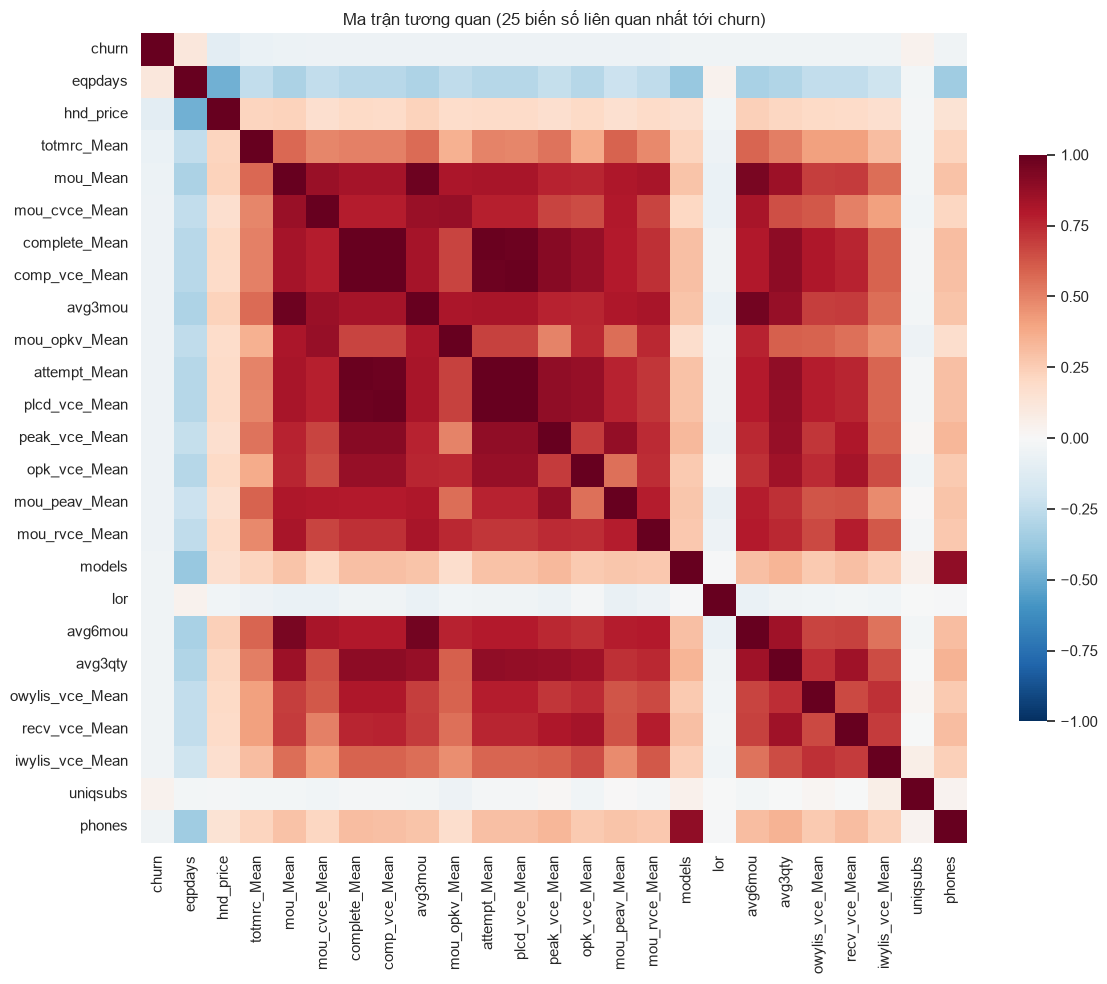

Tương quan tuyến tính với churn (|r| lớn nhất):


eqpdays          0.112
hnd_price       -0.103
totmrc_Mean     -0.069
mou_Mean        -0.057
mou_cvce_Mean   -0.052
complete_Mean   -0.052
comp_vce_Mean   -0.052
avg3mou         -0.050
mou_opkv_Mean   -0.049
attempt_Mean    -0.049
Name: churn, dtype: float64

Các cặp biến tương quan cao (|r| >= 0.8):


,biến 1,biến 2,|corr|
4113,totcalls,adjqty,1.000
4190,totmou,adjmou,1.000
4267,totrev,adjrev,0.998
1370,plcd_vce_Mean,attempt_Mean,0.998
1683,comp_vce_Mean,complete_Mean,0.998
...,...,...,...
1669,comp_vce_Mean,owylis_vce_Mean,0.810
2463,owylis_vce_Mean,complete_Mean,0.810
2221,mou_cvce_Mean,mou_peav_Mean,0.804
3574,complete_Mean,avg6mou,0.803


In [14]:
reporting.plot_correlation(cleaned, top_k=25, save="08_correlation")
plt.show()
print("Tương quan tuyến tính với churn (|r| lớn nhất):")
display(reporting.target_correlations(cleaned, top=10))
print("Các cặp biến tương quan cao (|r| >= 0.8):")
display(reporting.highly_correlated_pairs(cleaned, 0.8))

**Tóm tắt EDA.**
- Nhãn gần cân bằng (49,6% churn) ⇒ accuracy có ý nghĩa, nhưng ROC-AUC vẫn là chỉ số chính vì không phụ thuộc ngưỡng.
- Không biến nào tương quan tuyến tính mạnh với churn (|r| lớn nhất 0,11 — `eqpdays`, tiếp theo `hnd_price` −0,10)
  ⇒ bài toán khó, quan hệ phi tuyến; dự kiến mô hình cây vượt mô hình tuyến tính.
- 104 cặp biến có |r| ≥ 0,8 (vd. `totcalls`–`adjqty` = 1,00) ⇒ đa cộng tuyến mạnh: cần regularization cho Logistic
  Regression; PCA có thể nén nhiều chiều (thử ở 3.4).

## 2. Tiền xử lý & pipeline cấu hình được

### 2.1 Làm sạch (theo từng dòng — không học tham số nên không gây rò rỉ dữ liệu)
- Bỏ `Customer_ID`. Nhãn `churn` đã ở dạng 0/1.
- Thiếu ẩn (`"U"`, `"UNKW"`, `eqpdays < 0`) → `NaN` (tắt được bằng `treat_hidden_missing=False` để so sánh).

### 2.2 Chia train/test
Chia **stratified 80/20** (giữ nguyên tỷ lệ churn), `random_state=42`.

In [15]:
split_args = {"test_size": S.test_size, "random_state": S.seed}
data = load_dataset(treat_hidden_missing=True, **split_args)
data_unknown = load_dataset(treat_hidden_missing=False, **split_args)  # cho so sánh ở 3.1
X_train, X_test, y_train, y_test = data
# Thí nghiệm so sánh (mục 3, 7) dùng mẫu con phân tầng của train; mục 5 fit trên TOÀN BỘ train, đo TOÀN BỘ test
stage_data = subsample_train(data, S.stage_sample, S.seed)
stage_unknown = subsample_train(data_unknown, S.stage_sample, S.seed)
print(f"Train: {X_train.shape} | churn = {y_train.mean():.3f}")
print(f"Test : {X_test.shape} | churn = {y_test.mean():.3f}")
print(f"Mẫu con cho thí nghiệm so sánh: {stage_data[0].shape} | churn = {stage_data[2].mean():.3f}")

2026-11-25 10:13:53,378 INFO     modules.datasets.loader: Dữ liệu đã có: /Users/kunne/Downloads/ML/data/raw/Telecom_customer churn.csv


2026-11-25 10:13:54,009 INFO     modules.datasets.loader: Dữ liệu đã có: /Users/kunne/Downloads/ML/data/raw/Telecom_customer churn.csv


Train: (80000, 98) | churn = 0.496
Test : (20000, 98) | churn = 0.496
Mẫu con cho thí nghiệm so sánh: (30000, 98) | churn = 0.496


### 2.3 Pipeline
Mọi bước học tham số (imputer, encoder, scaler, PCA, mô hình) nằm trong **một `sklearn.Pipeline`**, nên khi
cross-validation, các bước này chỉ được `fit` trên phần train của mỗi fold → **không rò rỉ dữ liệu**.

```
Feature engineering ─► ColumnTransformer ─────────────────────────────────► Scaler ─► (PCA) ─► Mô hình
 (rev_per_minute,       ├─ số:        Imputer (+ cờ thiếu) ─► (log1p)          standard   0.90     logreg / linear_svm
  overage_share,        ├─ phân loại: Imputer ─► OneHot | Ordinal             minmax     0.95     knn / naive_bayes
  drop_block_rate,      └─ crclscod:  Imputer ─► Frequency | Target           none       0.99     random_forest / hist_gb
  mou_trend_3v6,                       | OneHot | drop                                            mlp (mở rộng)
  credit_class, …)
```
Mỗi thí nghiệm là một `PipelineConfig` (`modules/modeling/config.py`); mọi lựa chọn đều là tham số:

In [16]:
print(BASELINE)
build_pipeline(X_train, BASELINE)

PipelineConfig(name='baseline', treat_hidden_missing=True, num_imputer='median', cat_imputer='most_frequent', add_missing_indicator=True, cat_encoder='onehot', high_card_encoder='frequency', log_transform=False, scaler='standard', minmax_range=(0.0, 1.0), feature_selection=None, selection_k=40, selection_c=0.05, pca_variance=None, model='logreg', model_params={}, class_weight='balanced')


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('engineer', ...), ('columns', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set 

In [17]:
pre = build_preprocessing(X_train, BASELINE).fit(X_train, y_train)
names = pre.get_feature_names_out()
print(f"{X_train.shape[1]} cột gốc -> {len(names)} đặc trưng sau tiền xử lý")
print("Ví dụ:", list(names[:8]), "...", list(names[-6:]))

98 cột gốc -> 234 đặc trưng sau tiền xử lý
Ví dụ: ['rev_Mean', 'mou_Mean', 'totmrc_Mean', 'da_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'vceovr_Mean', 'datovr_Mean'] ... ['credit_class_V', 'credit_class_W', 'credit_class_Y', 'credit_class_Z', 'credit_class_infrequent_sklearn', 'crclscod_freq']


## 3. Thí nghiệm so sánh cấu hình
Mỗi giai đoạn thay đổi **một bước** của pipeline, giữ nguyên các bước còn lại, đánh giá bằng **stratified 3-fold
cross-validation** trên **mẫu con phân tầng 30.000 dòng của tập train** (mỗi fold kiểm tra ~10.000 mẫu, độ lệch chuẩn giữa
các fold được báo cáo kèm). Lấy mẫu con giúp notebook chạy được trên Colab (2 CPU); mô hình cuối ở mục 5 vẫn được huấn
luyện trên **toàn bộ** 80.000 dòng train.
Chỉ số chính: **ROC-AUC** (không phụ thuộc ngưỡng); kèm F1, Precision, Recall, Accuracy, PR-AUC.

**Quy tắc chọn (một sai số chuẩn).** Các phương án trong mỗi giai đoạn được xếp từ đơn giản/mặc định tới phức tạp. Cấu hình
được chọn là phương án **đầu tiên** có CV ROC-AUC không kém phương án cao nhất quá một sai số chuẩn (độ lệch chuẩn giữa các
fold / √3). Chênh lệch nhỏ hơn nhiễu giữa các fold không đủ lý do để chọn phương án phức tạp hơn. Cấu hình được chọn của
giai đoạn trước được mang sang giai đoạn sau (`modules/experiments/stages.py`).

Mô hình dùng cho 3.1–3.5: **Logistic Regression** (nhanh, nhạy với tiền xử lý → thấy rõ tác động của từng bước).

In [18]:
def show(df, extra, title, metric="cv_roc_auc"):
    display(summary_table(df, extra).sort_values(metric, ascending=False).reset_index(drop=True))
    reporting.plot_comparison(df, metric, title)
    plt.show()

### 3.1 Xử lý giá trị thiếu (imputation)

2026-11-25 10:13:59,998 INFO     modules.evaluation.experiment: [median + indicator                      ] CV ROC-AUC=0.6344 F1=0.5904 (4s)


2026-11-25 10:14:03,369 INFO     modules.evaluation.experiment: [mean + indicator                        ] CV ROC-AUC=0.6343 F1=0.5902 (3s)


2026-11-25 10:14:07,110 INFO     modules.evaluation.experiment: [most_frequent + indicator               ] CV ROC-AUC=0.6343 F1=0.5904 (4s)


2026-11-25 10:14:10,603 INFO     modules.evaluation.experiment: [median, no indicator                    ] CV ROC-AUC=0.6269 F1=0.5894 (3s)


2026-11-25 10:14:15,694 INFO     modules.evaluation.experiment: [median + cat='Missing'                  ] CV ROC-AUC=0.6353 F1=0.5906 (5s)


2026-11-25 10:14:20,410 INFO     modules.evaluation.experiment: [không xử lý thiếu ẩn                    ] CV ROC-AUC=0.6345 F1=0.5903 (5s)


,experiment,num_imputer,cat_imputer,add_missing_indicator,treat_hidden_missing,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_pr_auc
0,median + cat='Missing',median,constant,True,True,0.5965,0.5941,0.5871,0.5906,0.6353,0.6177
1,không xử lý thiếu ẩn,median,most_frequent,True,False,0.5958,0.5932,0.5874,0.5903,0.6345,0.6172
2,median + indicator,median,most_frequent,True,True,0.5962,0.5937,0.5871,0.5904,0.6344,0.6172
3,mean + indicator,mean,most_frequent,True,True,0.5961,0.5937,0.5869,0.5902,0.6343,0.6171
4,most_frequent + indicator,most_frequent,most_frequent,True,True,0.5961,0.5935,0.5874,0.5904,0.6343,0.6170
5,"median, no indicator",median,most_frequent,False,True,0.5917,0.5876,0.5914,0.5894,0.6269,0.6054


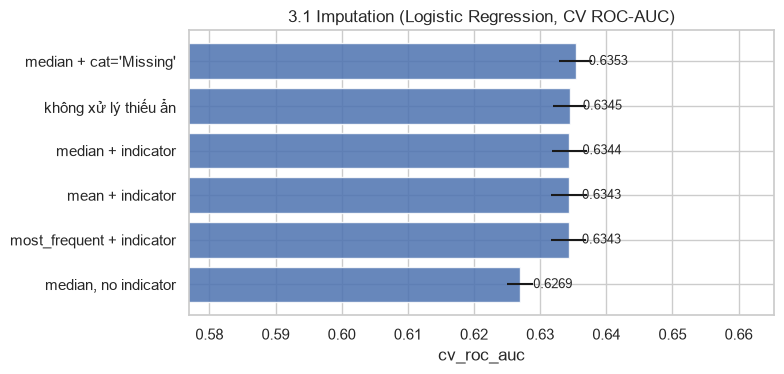

Chọn: {'num_imputer': 'median', 'cat_imputer': 'most_frequent', 'add_missing_indicator': True}


In [19]:
stage = imputation_stage(BASELINE, stage_data, stage_unknown, S.cv)
save_table(stage.table, "exp1_imputation")
show(
    stage.table,
    ["num_imputer", "cat_imputer", "add_missing_indicator", "treat_hidden_missing"],
    "3.1 Imputation (Logistic Regression, CV ROC-AUC)",
)
print(
    "Chọn:",
    {k: getattr(stage.config, k) for k in ("num_imputer", "cat_imputer", "add_missing_indicator")},
)

**Nhận xét 3.1.** Bỏ cờ thiếu làm ROC-AUC giảm rõ nhất (0,6344 → 0,6269, lớn hơn độ lệch chuẩn ≈ 0,003) — khớp EDA: việc
"bị thiếu" mang thông tin (kiểm định ở 3.7: p = 0,0003). Chọn mean / median / most_frequent cho cột số **không tạo khác biệt**
(chênh ≤ 0,0001). Điền `"Missing"` cho cột phân loại cao nhất (0,6353) nhưng chỉ hơn 0,0009 — nhỏ hơn một sai số chuẩn
(≈ 0,0014) — nên theo quy tắc chọn, giữ phương án đơn giản **median + cờ thiếu**. Đổi hay không đổi mã thiếu ẩn thành `NaN`
gần như như nhau với Logistic Regression (0,6344 so với 0,6345).

### 3.2 Mã hoá biến phân loại (encoding)

2026-11-25 10:14:25,023 INFO     modules.evaluation.experiment: [cat=onehot | crclscod=frequency         ] CV ROC-AUC=0.6344 F1=0.5904 (4s)


2026-11-25 10:14:30,247 INFO     modules.evaluation.experiment: [cat=onehot | crclscod=target            ] CV ROC-AUC=0.6345 F1=0.5903 (5s)


2026-11-25 10:14:35,046 INFO     modules.evaluation.experiment: [cat=onehot | crclscod=onehot            ] CV ROC-AUC=0.6344 F1=0.5906 (5s)


2026-11-25 10:14:39,388 INFO     modules.evaluation.experiment: [cat=onehot | crclscod=drop              ] CV ROC-AUC=0.6344 F1=0.5900 (4s)


2026-11-25 10:14:42,620 INFO     modules.evaluation.experiment: [cat=ordinal | crclscod=frequency        ] CV ROC-AUC=0.6339 F1=0.5910 (3s)


2026-11-25 10:14:45,464 INFO     modules.evaluation.experiment: [cat=ordinal | crclscod=target           ] CV ROC-AUC=0.6352 F1=0.5908 (3s)


2026-11-25 10:14:49,448 INFO     modules.evaluation.experiment: [cat=ordinal | crclscod=onehot           ] CV ROC-AUC=0.6347 F1=0.5914 (4s)


2026-11-25 10:14:52,160 INFO     modules.evaluation.experiment: [cat=ordinal | crclscod=drop             ] CV ROC-AUC=0.6339 F1=0.5915 (3s)


,experiment,cat_encoder,high_card_encoder,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_pr_auc
0,cat=ordinal | crclscod=target,ordinal,target,0.5971,0.5949,0.5867,0.5908,0.6352,0.6181
1,cat=ordinal | crclscod=onehot,ordinal,onehot,0.5966,0.5939,0.5889,0.5914,0.6347,0.6178
2,cat=onehot | crclscod=target,onehot,target,0.5964,0.5941,0.5866,0.5903,0.6345,0.6172
3,cat=onehot | crclscod=frequency,onehot,frequency,0.5962,0.5937,0.5871,0.5904,0.6344,0.6172
4,cat=onehot | crclscod=onehot,onehot,onehot,0.5963,0.5937,0.5875,0.5906,0.6344,0.6170
5,cat=onehot | crclscod=drop,onehot,drop,0.5961,0.5938,0.5864,0.5900,0.6344,0.6172
6,cat=ordinal | crclscod=frequency,ordinal,frequency,0.5972,0.5949,0.5873,0.5910,0.6339,0.6171
7,cat=ordinal | crclscod=drop,ordinal,drop,0.5977,0.5956,0.5875,0.5915,0.6339,0.6170


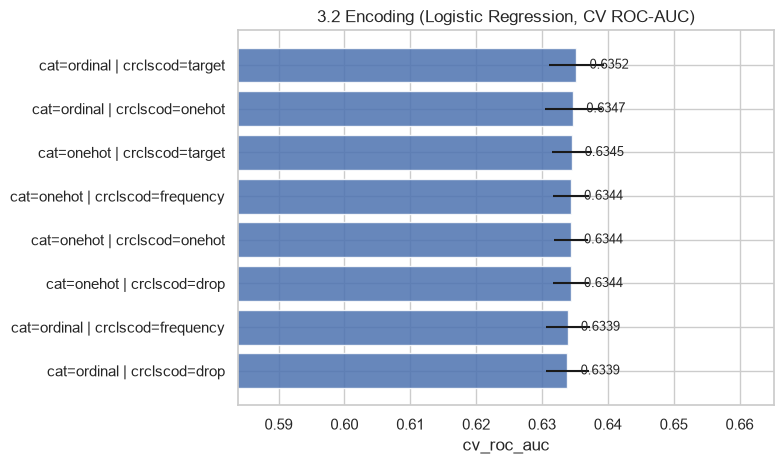

Chọn: {'cat_encoder': 'onehot', 'high_card_encoder': 'frequency'}


In [20]:
stage = encoding_stage(stage.config, stage_data, S.cv)
save_table(stage.table, "exp2_encoding")
show(
    stage.table,
    ["cat_encoder", "high_card_encoder"],
    "3.2 Encoding (Logistic Regression, CV ROC-AUC)",
)
print("Chọn:", {k: getattr(stage.config, k) for k in ("cat_encoder", "high_card_encoder")})

**Nhận xét 3.2.** Mọi cách encoding cho ROC-AUC trong khoảng 0,6339–0,6352, chênh lệch **nhỏ hơn độ lệch chuẩn** (0,003–0,004)
⇒ với Logistic Regression, encoding không phải nút thắt (kiểm định ở 3.7: one-hot + frequency so với ordinal + target,
p = 0,80). Theo quy tắc chọn, giữ **one-hot cho cột phân loại thường + frequency encoding cho `crclscod`**: one-hot đúng bản chất
biến định danh (không áp đặt thứ tự giả như ordinal) và frequency chỉ thêm 1 cột cho 54 mã. Bỏ hẳn `crclscod` cũng không mất
gì (0,6344) vì `credit_class` (chữ cái đầu, do feature engineering tạo) giữ phần lớn thông tin.

### 3.3 Chuẩn hoá dữ liệu (scaling) và biến đổi log
EDA cho thấy nhiều biến số lệch phải mạnh và có nhiều ngoại lai, nên ngoài `StandardScaler` / `MinMaxScaler`
(`feature_range` (0, 1) và (−1, 1)) còn thử biến đổi **log1p giữ dấu** `sign(x)·log(1+|x|)` trước khi scale.
So sánh trên hai mô hình nhạy với thang đo: Logistic Regression và k-NN (dựa trên khoảng cách).

/Users/kunne/Downloads/ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


/Users/kunne/Downloads/ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


/Users/kunne/Downloads/ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
2026-11-25 10:15:32,662 INFO     modules.evaluation.experiment: [logreg | none                           ] CV ROC-AUC=0.6108 F1=0.5714 (40s)


2026-11-25 10:15:36,542 INFO     modules.evaluation.experiment: [logreg | standard                       ] CV ROC-AUC=0.6344 F1=0.5904 (4s)


2026-11-25 10:15:39,732 INFO     modules.evaluation.experiment: [logreg | minmax(0.0, 1.0)               ] CV ROC-AUC=0.6342 F1=0.5877 (3s)


2026-11-25 10:15:47,707 INFO     modules.evaluation.experiment: [logreg | minmax(-1.0, 1.0)              ] CV ROC-AUC=0.6344 F1=0.5904 (8s)


... (5 outputs left out)

2026-11-25 10:16:14,985 INFO     modules.evaluation.experiment: [knn | minmax(-1.0, 1.0)                 ] CV ROC-AUC=0.5488 F1=0.5043 (5s)


2026-11-25 10:16:19,900 INFO     modules.evaluation.experiment: [knn | log + standard                    ] CV ROC-AUC=0.5776 F1=0.5193 (5s)


2026-11-25 10:16:24,887 INFO     modules.evaluation.experiment: [knn | log + minmax(0.0, 1.0)            ] CV ROC-AUC=0.5652 F1=0.5069 (5s)


,experiment,model,log_transform,scaler,minmax_range,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_pr_auc
0,logreg | log + standard,logreg,True,standard,"(0.0, 1.0)",0.6017,0.6004,0.5877,0.5939,0.6433,0.6301
1,"logreg | log + minmax(0.0, 1.0)",logreg,True,minmax,"(0.0, 1.0)",0.6006,0.5995,0.5852,0.5922,0.6422,0.6297
2,logreg | standard,logreg,False,standard,"(0.0, 1.0)",0.5962,0.5937,0.5871,0.5904,0.6344,0.6172
3,"logreg | minmax(-1.0, 1.0)",logreg,False,minmax,"(-1.0, 1.0)",0.5967,0.5945,0.5863,0.5904,0.6344,0.6182
4,"logreg | minmax(0.0, 1.0)",logreg,False,minmax,"(0.0, 1.0)",0.5946,0.5926,0.5830,0.5877,0.6342,0.6189
5,logreg | none,logreg,False,none,"(0.0, 1.0)",0.5812,0.5799,0.5633,0.5714,0.6108,0.5848
6,knn | log + standard,knn,True,standard,"(0.0, 1.0)",0.5546,0.5583,0.4854,0.5193,0.5776,0.5731
7,knn | standard,knn,False,standard,"(0.0, 1.0)",0.5480,0.5518,0.4692,0.5072,0.5716,0.5667
8,"knn | log + minmax(0.0, 1.0)",knn,True,minmax,"(0.0, 1.0)",0.5468,0.5501,0.4700,0.5069,0.5652,0.5621
9,knn | none,knn,False,none,"(0.0, 1.0)",0.5457,0.5444,0.5111,0.5272,0.5646,0.5509


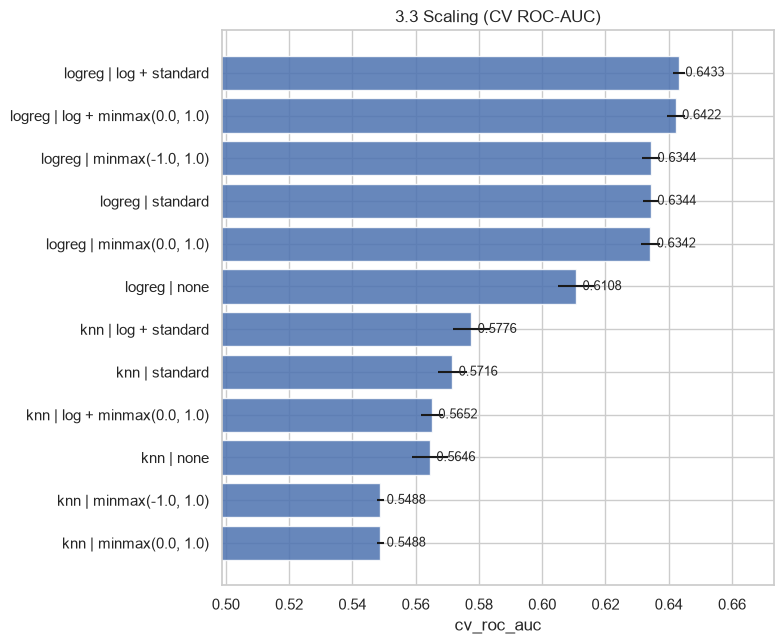

Chọn (theo Logistic Regression): {'scaler': 'standard', 'minmax_range': (0.0, 1.0), 'log_transform': True}


In [21]:
stage = scaling_stage(stage.config, stage_data, S.cv)
save_table(stage.table, "exp3_scaling")
show(stage.table, ["model", "log_transform", "scaler", "minmax_range"], "3.3 Scaling (CV ROC-AUC)")
print(
    "Chọn (theo Logistic Regression):",
    {k: getattr(stage.config, k) for k in ("scaler", "minmax_range", "log_transform")},
)

**Nhận xét 3.3.** Đây là bước tiền xử lý có tác động lớn nhất:
- Logistic Regression **không scale: 0,6108**, và bộ tối ưu lbfgs **không hội tụ** sau 2000 vòng (cảnh báo `ConvergenceWarning`
  ở trên là có chủ đích — minh hoạ vì sao phải scale). StandardScaler / MinMax: ≈ 0,634 → **log1p + StandardScaler: 0,6433**
  (+0,009 so với chỉ scale). Biến đổi log thu hẹp ngoại lai mà EDA đã phát hiện (kiểm định ở 3.7: p = 0,001).
  `feature_range` (0, 1) hay (−1, 1) không đổi kết quả (0,6342 so với 0,6344 — MinMax chỉ dịch/giãn tuyến tính).
- k-NN kém xa Logistic Regression ở mọi cách scale (cao nhất 0,578 với log + StandardScaler; MinMax còn tệ hơn không scale, nhiều
  khả năng vì ngoại lai nén phần lớn giá trị số về gần 0 nên các cột 0/1 — one-hot, cờ thiếu — lấn át khoảng cách): khoảng cách Euclid trên ~230 chiều nhiễu ("lời nguyền số chiều").

### 3.4 Giảm số chiều (PCA)
PCA giữ lại 90% / 95% / 99% phương sai, so sánh với không dùng PCA.

2026-11-25 10:16:31,168 INFO     modules.evaluation.experiment: [logreg | PCA=None                       ] CV ROC-AUC=0.6433 F1=0.5939 (4s)


2026-11-25 10:16:33,747 INFO     modules.evaluation.experiment: [logreg | PCA=0.9                        ] CV ROC-AUC=0.6278 F1=0.5855 (2s)


2026-11-25 10:16:36,336 INFO     modules.evaluation.experiment: [logreg | PCA=0.95                       ] CV ROC-AUC=0.6320 F1=0.5862 (2s)


2026-11-25 10:16:39,229 INFO     modules.evaluation.experiment: [logreg | PCA=0.99                       ] CV ROC-AUC=0.6370 F1=0.5906 (2s)


2026-11-25 10:16:44,339 INFO     modules.evaluation.experiment: [knn | PCA=None                          ] CV ROC-AUC=0.5776 F1=0.5193 (4s)


2026-11-25 10:16:48,174 INFO     modules.evaluation.experiment: [knn | PCA=0.9                           ] CV ROC-AUC=0.5785 F1=0.5246 (3s)


2026-11-25 10:16:52,198 INFO     modules.evaluation.experiment: [knn | PCA=0.95                          ] CV ROC-AUC=0.5752 F1=0.5175 (3s)


2026-11-25 10:16:56,638 INFO     modules.evaluation.experiment: [knn | PCA=0.99                          ] CV ROC-AUC=0.5781 F1=0.5218 (4s)


,experiment,model,pca_variance,n_features_after_preprocess,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_pr_auc
0,logreg | PCA=None,logreg,NaN,231,0.6017,0.6004,0.5877,0.5939,0.6433,0.6301
1,logreg | PCA=0.99,logreg,0.99,145,0.5982,0.5966,0.5848,0.5906,0.6370,0.6254
2,logreg | PCA=0.95,logreg,0.95,121,0.5946,0.5933,0.5793,0.5862,0.6320,0.6207
3,logreg | PCA=0.9,logreg,0.90,105,0.5929,0.5909,0.5803,0.5855,0.6278,0.6167
4,knn | PCA=0.9,knn,0.90,105,0.5536,0.5556,0.4969,0.5246,0.5785,0.5738
5,knn | PCA=0.99,knn,0.99,145,0.5553,0.5587,0.4895,0.5218,0.5781,0.5733
6,knn | PCA=None,knn,NaN,231,0.5546,0.5583,0.4854,0.5193,0.5776,0.5731
7,knn | PCA=0.95,knn,0.95,121,0.5498,0.5519,0.4871,0.5175,0.5752,0.5708


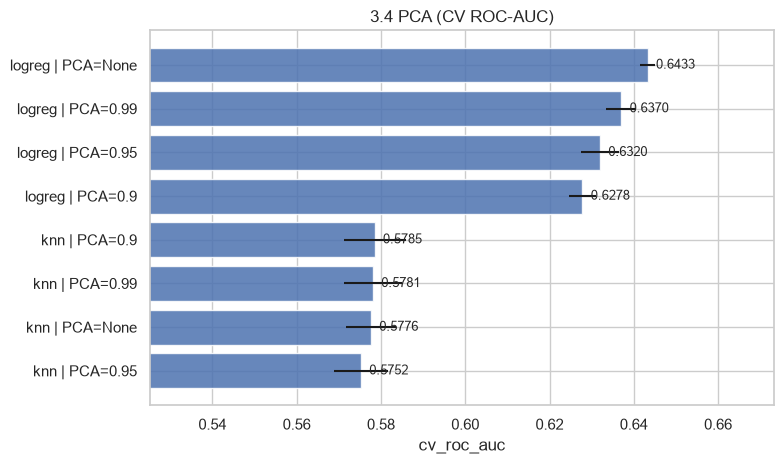

Chọn PCA: None


In [22]:
stage = pca_stage(stage.config, stage_data, S.cv)
save_table(stage.table, "exp4_pca")
show(stage.table, ["model", "pca_variance", "n_features_after_preprocess"], "3.4 PCA (CV ROC-AUC)")
print("Chọn PCA:", stage.config.pca_variance)

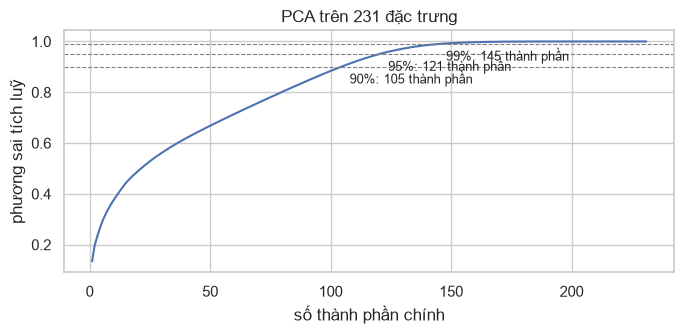

In [23]:
# Phương sai tích luỹ của PCA (StandardScaler, fit trên train)
reporting.plot_pca_variance(
    pca_explained_variance(stage.config, stage_data), save="09_pca_variance"
)
plt.show()

**Nhận xét 3.4.** PCA **làm giảm** ROC-AUC của Logistic Regression (0,6433 → 0,6370 / 0,6320 / 0,6278 khi giữ 99% / 95% / 90%
phương sai, tương ứng 145 / 121 / 105 thành phần từ 231 đặc trưng). PCA chọn hướng có phương sai lớn, không phải hướng phân
biệt churn, nên bỏ mất tín hiệu yếu (kiểm định ở 3.7: PCA 95% giảm 0,009, p = 0,005). Với k-NN, PCA không đổi kết quả
(0,575–0,579). ⇒ Không dùng PCA trong cấu hình cuối; PCA vẫn hữu ích khi cần nén đặc trưng (biến thể `pca95` lưu ở mục 6).

### 3.5 Lựa chọn đặc trưng (feature selection)
Khác với PCA (tạo trục mới), lựa chọn đặc trưng **giữ nguyên một tập con các cột gốc** — dễ giải thích hơn:
- **Lọc (filter)**: `SelectKBest` theo ANOVA F (quan hệ tuyến tính) hoặc mutual information (cả phi tuyến), giữ k = 20/40/80.
- **Nhúng (embedded)**: `SelectFromModel` với Logistic Regression L1 — L1 đẩy hệ số của cột kém về 0.

Bước chọn nằm trong pipeline (sau scaler) nên được fit lại trên phần train của từng fold → không rò rỉ.

2026-11-25 10:17:03,543 INFO     modules.evaluation.experiment: [không chọn                              ] CV ROC-AUC=0.6433 F1=0.5939 (4s)


2026-11-25 10:17:06,049 INFO     modules.evaluation.experiment: [ANOVA F, k=20                           ] CV ROC-AUC=0.6069 F1=0.5607 (2s)


2026-11-25 10:17:08,674 INFO     modules.evaluation.experiment: [ANOVA F, k=40                           ] CV ROC-AUC=0.6222 F1=0.5742 (2s)


2026-11-25 10:17:11,773 INFO     modules.evaluation.experiment: [ANOVA F, k=80                           ] CV ROC-AUC=0.6397 F1=0.5933 (2s)


2026-11-25 10:17:54,207 INFO     modules.evaluation.experiment: [mutual info, k=40                       ] CV ROC-AUC=0.6304 F1=0.5828 (27s)


2026-11-25 10:18:09,356 INFO     modules.evaluation.experiment: [L1 (C=0.05)                             ] CV ROC-AUC=0.6413 F1=0.5917 (12s)


2026-11-25 10:18:14,412 INFO     modules.evaluation.experiment: [L1 (C=0.01)                             ] CV ROC-AUC=0.6389 F1=0.5928 (3s)


,experiment,feature_selection,selection_k,selection_c,n_features_after_preprocess,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_pr_auc
0,không chọn,NaN,40,0.05,231,0.6017,0.6004,0.5877,0.5939,0.6433,0.6301
1,L1 (C=0.05),l1,40,0.05,158,0.6000,0.5988,0.5848,0.5917,0.6413,0.6280
2,"ANOVA F, k=80",kbest_f,80,0.05,80,0.6005,0.5988,0.5880,0.5933,0.6397,0.6255
3,L1 (C=0.01),l1,40,0.01,86,0.6006,0.5991,0.5868,0.5928,0.6389,0.6255
4,"mutual info, k=40",kbest_mi,40,0.05,40,0.5933,0.5928,0.5738,0.5828,0.6304,0.6153
5,"ANOVA F, k=40",kbest_f,40,0.05,40,0.5892,0.5903,0.5591,0.5742,0.6222,0.6111
6,"ANOVA F, k=20",kbest_f,20,0.05,20,0.5771,0.5777,0.5453,0.5607,0.6069,0.6005


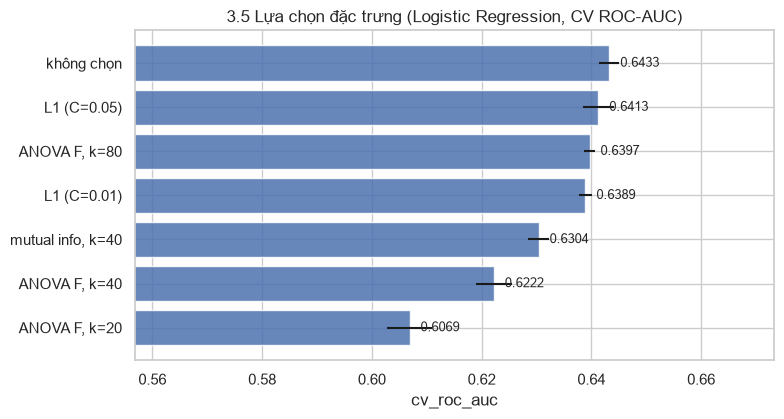

Chọn: {'feature_selection': None, 'selection_k': 40, 'selection_c': 0.05}


In [24]:
stage = selection_stage(stage.config, stage_data, S.cv)
save_table(stage.table, "exp4b_selection")
show(
    stage.table,
    ["feature_selection", "selection_k", "selection_c", "n_features_after_preprocess"],
    "3.5 Lựa chọn đặc trưng (Logistic Regression, CV ROC-AUC)",
)
print(
    "Chọn:",
    {k: getattr(stage.config, k) for k in ("feature_selection", "selection_k", "selection_c")},
)

**Nhận xét 3.5.** Không phương pháp chọn đặc trưng nào **vượt** dùng đủ 231 đặc trưng (0,6433):
- **L1 (nhúng)** giữ 158 cột (C = 0,05) chỉ mất 0,0020 ROC-AUC, giữ 86 cột (C = 0,01) mất 0,0044 ⇒ khoảng 1/3 – 2/3 số đặc trưng
  gần như không mang thêm thông tin (khớp 104 cặp tương quan ≥ 0,8 ở EDA và các cột one-hot hiếm). L1 hữu ích khi cần mô hình gọn.
- **Lọc theo ANOVA F** giảm mạnh khi k nhỏ (k = 20: 0,6069; k = 80: 0,6397): F chỉ đo quan hệ tuyến tính của từng cột riêng lẻ,
  bỏ sót cột yếu riêng lẻ nhưng hữu ích khi kết hợp. **Mutual information** (k = 40: 0,6304) tốt hơn ANOVA F cùng k (0,6222) vì
  bắt được quan hệ phi tuyến.
⇒ Cấu hình cuối không chọn đặc trưng; regularization của Logistic Regression đã tự xử lý đặc trưng thừa.

### 3.6 So sánh mô hình
Dùng tiền xử lý đã chọn. **Mốc Dummy** dự đoán xác suất churn bằng tỷ lệ churn của train cho mọi khách hàng (không dùng đặc
trưng) — mọi mô hình phải vượt mốc này mới có ý nghĩa. Mô hình cây (Random Forest, Gradient Boosting của sklearn, **LightGBM**)
không cần scaling/PCA/chọn đặc trưng. LightGBM khác HistGradientBoosting ở bagging theo dòng và lấy mẫu cột.
Thêm so sánh `class_weight="balanced"` và không dùng (dữ liệu gần cân bằng 50/50 nên dự kiến khác biệt nhỏ).

2026-11-25 10:18:16,165 INFO     modules.evaluation.experiment: [Baseline (Dummy)                        ] CV ROC-AUC=0.5000 F1=0.0000 (2s)


2026-11-25 10:18:20,498 INFO     modules.evaluation.experiment: [Logistic Regression                     ] CV ROC-AUC=0.6433 F1=0.5939 (4s)


2026-11-25 10:18:24,007 INFO     modules.evaluation.experiment: [Linear SVM                              ] CV ROC-AUC=0.6394 F1=0.5799 (4s)


2026-11-25 10:18:28,407 INFO     modules.evaluation.experiment: [k-NN (k=25)                             ] CV ROC-AUC=0.5776 F1=0.5193 (4s)


2026-11-25 10:18:30,190 INFO     modules.evaluation.experiment: [Gaussian Naive Bayes                    ] CV ROC-AUC=0.5781 F1=0.3379 (2s)


2026-11-25 10:18:37,353 INFO     modules.evaluation.experiment: [Random Forest                           ] CV ROC-AUC=0.6746 F1=0.6269 (7s)


... (2 outputs left out)

2026-11-25 10:19:46,058 INFO     modules.evaluation.experiment: [Logistic Regression (no class_weight)   ] CV ROC-AUC=0.6433 F1=0.5876 (4s)


2026-11-25 10:19:53,036 INFO     modules.evaluation.experiment: [Random Forest (no class_weight)         ] CV ROC-AUC=0.6748 F1=0.6218 (7s)


2026-11-25 10:20:01,170 INFO     modules.evaluation.experiment: [Gradient Boosting (no class_weight)     ] CV ROC-AUC=0.6865 F1=0.6277 (8s)


,experiment,model,class_weight,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_pr_auc
0,LightGBM,lightgbm,balanced,0.6316,0.6281,0.6294,0.6287,0.6871,0.6745
1,Gradient Boosting (Hist),hist_gb,balanced,0.6322,0.6271,0.6363,0.6317,0.6865,0.6742
2,Gradient Boosting (no class_weight),hist_gb,NaN,0.6321,0.6297,0.6258,0.6277,0.6865,0.6731
3,Random Forest (no class_weight),random_forest,NaN,0.6221,0.6170,0.6269,0.6218,0.6748,0.6610
4,Random Forest,random_forest,balanced,0.6217,0.6132,0.6413,0.6269,0.6746,0.6608
5,Logistic Regression,logreg,balanced,0.6017,0.6004,0.5877,0.5939,0.6433,0.6301
6,Logistic Regression (no class_weight),logreg,NaN,0.6006,0.6018,0.5741,0.5876,0.6433,0.6301
7,Linear SVM,linear_svm,balanced,0.6000,0.6047,0.5572,0.5799,0.6394,0.6269
8,Gaussian Naive Bayes,naive_bayes,balanced,0.5363,0.5782,0.2390,0.3379,0.5781,0.5640
9,k-NN (k=25),knn,balanced,0.5546,0.5583,0.4854,0.5193,0.5776,0.5731


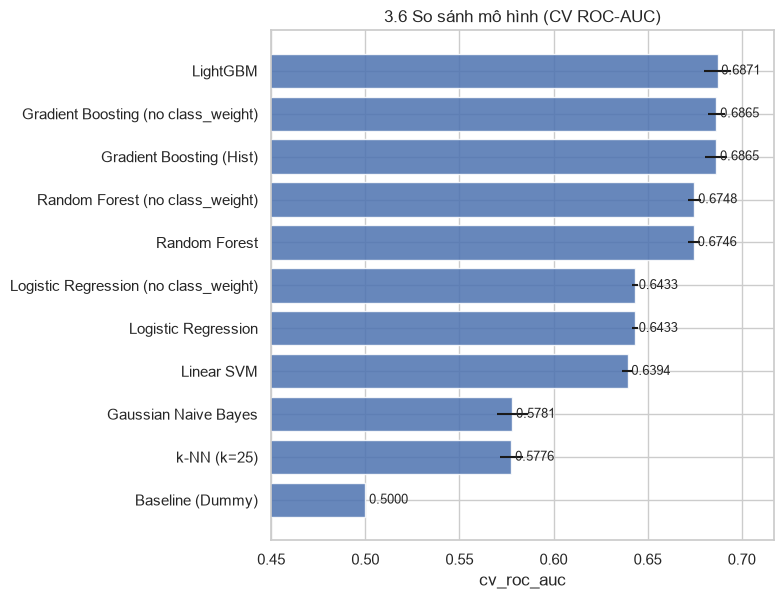

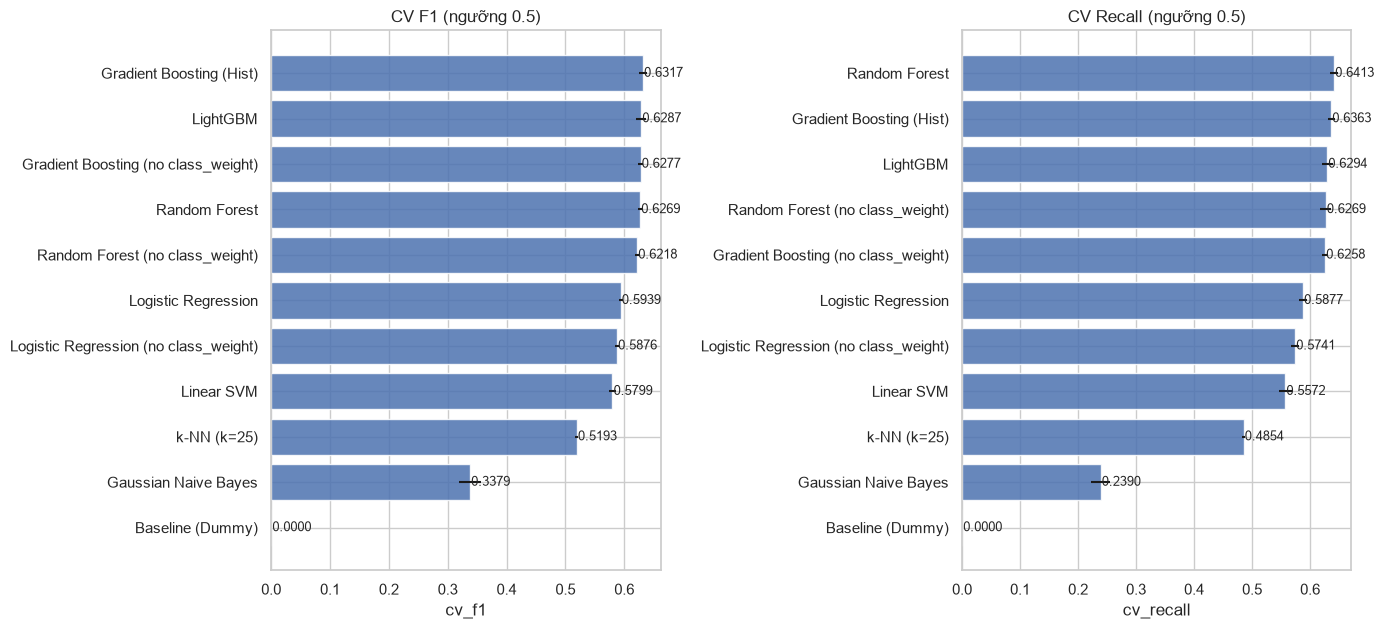

In [25]:
BEST = stage.config
res_models = model_stage(BEST, stage_data, S.cv)
save_table(res_models, "exp5_models")
show(res_models, ["model", "class_weight"], "3.6 So sánh mô hình (CV ROC-AUC)")
reporting.plot_metric_panels(
    res_models,
    ["cv_f1", "cv_recall"],
    ["CV F1 (ngưỡng 0.5)", "CV Recall (ngưỡng 0.5)"],
    save="10_models_f1_recall",
)
plt.show()

**Nhận xét 3.6.**
- **Mốc Dummy**: ROC-AUC 0,5 và F1 = 0 ở ngưỡng 0,5 (xác suất 0,496 < 0,5 nên đoán "không churn" cho tất cả, accuracy 50,4%).
  Mọi mô hình đều vượt mốc, nhưng accuracy của mô hình tốt nhất chỉ hơn mốc khoảng 13 điểm % ⇒ bài toán khó.
- **Mô hình cây tăng cường vượt rõ mô hình tuyến tính**: LightGBM 0,6871 và Gradient Boosting 0,6865 (chênh 0,0006, nhỏ hơn
  nhiều độ lệch chuẩn ≈ 0,006 ⇒ tương đương), Random Forest 0,6746, so với Logistic Regression 0,6433 và Linear SVM 0,6394 —
  xác nhận quan hệ phi tuyến/tương tác giữa các biến mà EDA gợi ý (kiểm định ở 3.7).
- k-NN (0,578) và Gaussian Naive Bayes (0,578) kém nhất: NB giả định đặc trưng độc lập, phân phối chuẩn — sai nặng với dữ liệu
  lệch và đa cộng tuyến; F1 chỉ 0,34 vì recall thấp ở ngưỡng 0,5.
- `class_weight="balanced"` không đổi ROC-AUC (dữ liệu 50/50), chỉ dịch nhẹ cân bằng precision/recall.

### 3.7 Kiểm định thống kê cho các kết luận chính
Nhiều chênh lệch ở trên chỉ vài phần nghìn ROC-AUC. Để biết chênh lệch nào **thật** và chênh lệch nào chỉ là nhiễu do cách
chia fold, mỗi cặp được đánh giá trên **cùng các fold** của CV 3-fold lặp 3 lần (9 lần đo), rồi kiểm định bằng
**t-test ghép cặp hiệu chỉnh Nadeau–Bengio**. Hiệu chỉnh này cần thiết vì các fold dùng chung dữ liệu train, nên
t-test thông thường đánh giá thấp phương sai (quá lạc quan).

In [26]:
sig = significance_stage(BEST, stage_data, S)
save_table(sig, "exp5b_significance")
display(sig)

,câu hỏi,A,B,auc_A,auc_B,chênh A-B,t,p,có ý nghĩa (p<0.05)
0,Cờ giá trị thiếu có giúp?,cấu hình chọn (LR),không cờ thiếu,0.6437,0.6400,0.0037,6.1624,0.0003,True
1,Log-transform có giúp?,cấu hình chọn (LR),không log,0.6437,0.6358,0.0079,4.8509,0.0013,True
2,Encoding có quan trọng?,cấu hình chọn (LR),ordinal + target,0.6437,0.6432,0.0005,0.2563,0.8042,False
3,PCA 95% có hại?,cấu hình chọn (LR),PCA 95%,0.6437,0.6344,0.0093,3.9113,0.0045,True
4,Lựa chọn đặc trưng có tác động?,cấu hình chọn (LR),"ANOVA F, k=40",0.6437,0.6197,0.0240,4.1645,0.0031,True
5,GB hơn RF?,Gradient Boosting,Random Forest,0.6884,0.6747,0.0137,4.3031,0.0026,True
6,GB hơn LR?,Gradient Boosting,cấu hình chọn (LR),0.6884,0.6437,0.0446,10.3610,0.0000,True


**Nhận xét 3.7 (kiểm định).** Với CV 3-fold lặp 3 lần và t-test hiệu chỉnh:
- **Có ý nghĩa (p < 0,05):** cờ giá trị thiếu (+0,0037, p = 0,0003), log-transform (+0,0079, p = 0,001), PCA 95% làm giảm
  (−0,0093, p = 0,005), chọn đặc trưng ANOVA F k = 40 làm giảm (−0,024, p = 0,003), **Gradient Boosting hơn Random Forest**
  (+0,014, p = 0,003) và **hơn Logistic Regression** (+0,045, p < 0,0001).
- **Không có ý nghĩa:** cách encoding (+0,0005, p = 0,80) — xác nhận nhận xét ở 3.2.
- LightGBM và Gradient Boosting chênh 0,0006 trên CV ở 3.6, nhỏ hơn nhiều độ lệch chuẩn giữa các fold ⇒ coi là **tương đương**;
  cặp này không đưa vào kiểm định để giữ thời gian chạy trên Colab.
⇒ Các kết luận của báo cáo dựa trên khác biệt đã kiểm định, không phải nhiễu do cách chia fold.

## 4. Tinh chỉnh siêu tham số
`RandomizedSearchCV` (3-fold, 5 tổ hợp mỗi mô hình) cho Logistic Regression, Random Forest và Gradient Boosting, chạy trên
**mẫu con phân tầng 20.000 dòng của tập train** để notebook chạy trong thời gian hợp lý trên Colab. Không gian tham số nằm
trong `configs/default.yaml`. **LightGBM** giữ tham số cố định (1500 cây, learning rate 0,02, 31 lá, bagging 0,8, lấy mẫu cột
0,7 — cấu hình "nhiều cây, bước học nhỏ" thông dụng) và không tuning trong notebook vì chi phí (~10 phút); CV ở 3.6 cho thấy
cấu hình này đã ngang Gradient Boosting.

In [27]:
TUNED, tuning_tables = tuning_stage(BEST, data, S.tuning, S.seed)
for key, table in tuning_tables.items():
    save_table(table, f"exp6_tuning_{key}")
    print(
        f"\n{TUNED[key].name}: {TUNED[key].model_params} | CV ROC-AUC = {table.mean_test_score[0]:.4f}"
    )
    display(table.head(5).round(4))


Logistic Regression (tuned): {'C': 0.1} | CV ROC-AUC = 0.6427


,param_model__C,mean_test_score,std_test_score
0,0.100,0.6427,0.0010
1,1.000,0.6426,0.0010
2,10.000,0.6425,0.0010
3,0.010,0.6414,0.0011
4,0.001,0.6390,0.0016



Random Forest (tuned): {'n_estimators': 150, 'min_samples_leaf': 10, 'max_features': 0.5, 'max_depth': 10} | CV ROC-AUC = 0.6715


,param_model__n_estimators,param_model__min_samples_leaf,param_model__max_features,param_model__max_depth,mean_test_score,std_test_score
0,150,10,0.5,10,0.6715,0.0028
1,150,50,0.3,20,0.6708,0.0029
2,150,20,sqrt,14,0.6683,0.0013
3,150,5,sqrt,10,0.6665,0.0012
4,150,20,sqrt,10,0.6657,0.0012



Gradient Boosting (Hist) (tuned): {'min_samples_leaf': 50, 'max_leaf_nodes': 31, 'learning_rate': 0.03, 'l2_regularization': 1.0} | CV ROC-AUC = 0.6856


,param_model__min_samples_leaf,param_model__max_leaf_nodes,param_model__learning_rate,param_model__l2_regularization,mean_test_score,std_test_score
0,50,31,0.03,1.0,0.6856,0.0010
1,20,31,0.03,1.0,0.6849,0.0006
2,20,15,0.03,0.0,0.6830,0.0015
3,20,15,0.10,0.0,0.6802,0.0026
4,50,31,0.10,0.0,0.6800,0.0011


**Nhận xét 4.** Tinh chỉnh cải thiện ít: Gradient Boosting tốt nhất với `learning_rate=0.03`, `max_leaf_nodes=31`,
`min_samples_leaf=50`, `l2_regularization=1.0` (CV ROC-AUC 0,6856 trên mẫu con 20k); Random Forest tốt nhất với cây nông
(`max_depth=10`, `max_features=0.5`, `min_samples_leaf=10`; 0,6715); Logistic Regression `C=0.1` (0,6427) nhưng C = 0,1 / 1 / 10
gần như bằng nhau. Mức cải thiện nhỏ cho thấy giới hạn nằm ở tín hiệu trong dữ liệu hơn là ở siêu tham số.

## 5. Đánh giá cuối cùng trên tập test
1. Fit lại mỗi mô hình đã tinh chỉnh (và mốc Dummy) trên **toàn bộ tập train**.
2. Chọn ngưỡng phân loại bằng xác suất *out-of-fold* trên mẫu con 30.000 dòng của train (không dùng tập test), theo hai tiêu chí:
   - `oof_balanced` — **tối đa balanced accuracy** = (TPR + TNR)/2, tương đương chỉ số Youden J: ngưỡng chính.
   - `oof_f1` — tối đa F1, giữ lại để so sánh (xem nhận xét: F1 không phải tiêu chí tốt cho dữ liệu 50/50).
3. Đánh giá **một lần** trên tập test, ở ngưỡng mặc định 0,5 và hai ngưỡng đã chọn.

,model,threshold_rule,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Baseline (Dummy),default,0.50,0.5044,0.0000,0.0000,0.0000,0.5000,0.4956
1,Baseline (Dummy),oof_balanced,0.05,0.4956,0.4956,1.0000,0.6627,0.5000,0.4956
2,Baseline (Dummy),oof_f1,0.05,0.4956,0.4956,1.0000,0.6627,0.5000,0.4956
3,Logistic Regression (tuned),default,0.50,0.6096,0.6079,0.5979,0.6028,0.6507,0.6380
4,Logistic Regression (tuned),oof_balanced,0.49,0.6086,0.6008,0.6263,0.6133,0.6507,0.6380
5,Logistic Regression (tuned),oof_f1,0.34,0.5476,0.5245,0.9327,0.6714,0.6507,0.6380
6,Random Forest (tuned),default,0.50,0.6278,0.6185,0.6499,0.6338,0.6858,0.6774
7,Random Forest (tuned),oof_balanced,0.51,0.6280,0.6273,0.6143,0.6207,0.6858,0.6774
8,Random Forest (tuned),oof_f1,0.37,0.5876,0.5508,0.9109,0.6865,0.6858,0.6774
9,Gradient Boosting (Hist) (tuned),default,0.50,0.6417,0.6353,0.6502,0.6427,0.7008,0.6924


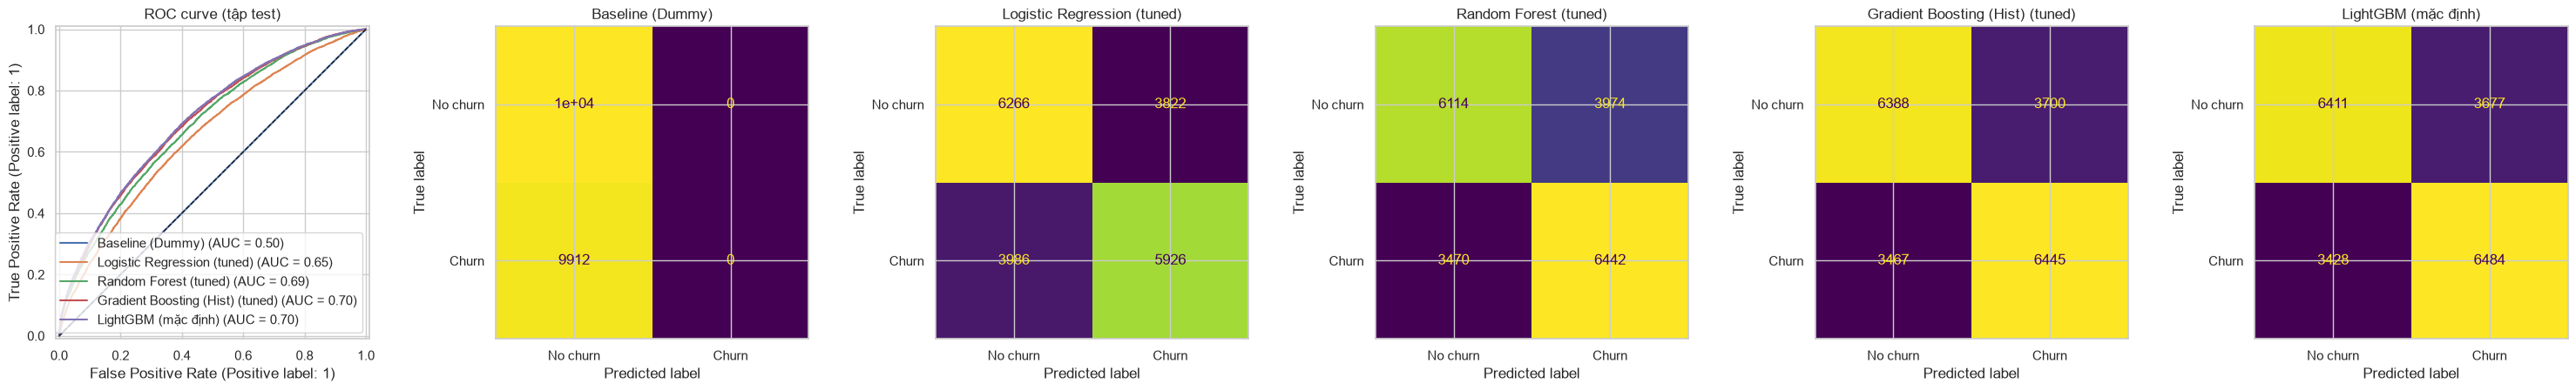

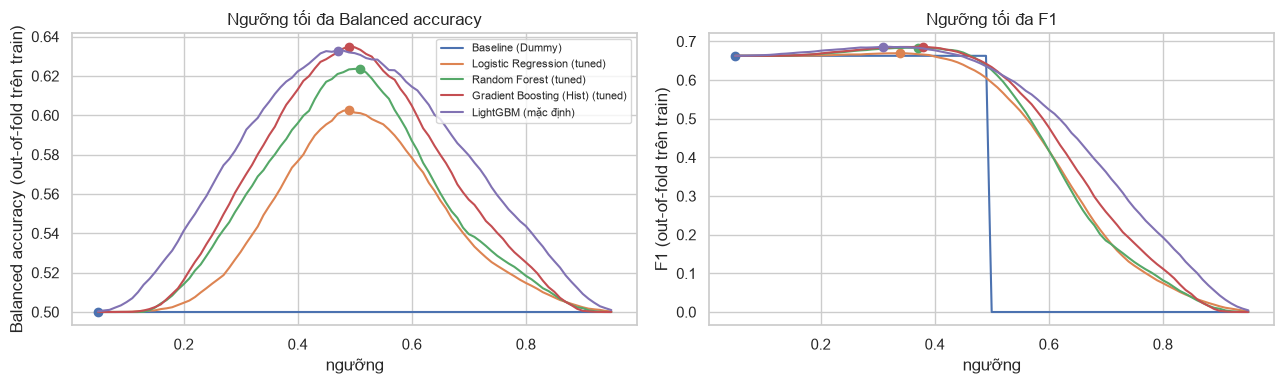

In [28]:
# kèm mốc Dummy (dự đoán theo tỷ lệ lớp) để thấy mỗi mô hình hơn "đoán mò" bao nhiêu
final = final_stage([baseline_config(BEST), *TUNED.values()], data, S)
display(final.table)
reporting.plot_final_models(final.models, X_test, y_test, save="11_final_roc_confusion")
plt.show()
reporting.plot_threshold_curves(final.curves, save="12_threshold_tuning")
plt.show()

Mô hình chọn theo CV: LightGBM (mặc định)


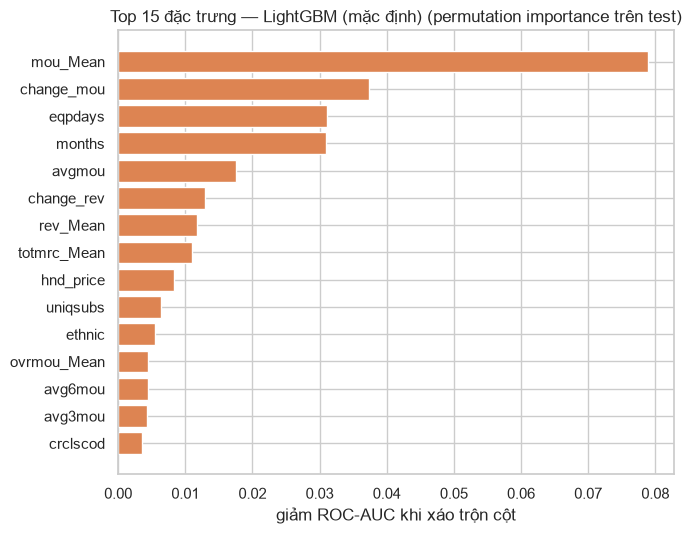

In [29]:
# chọn theo CV ở 3.6 (cùng mẫu con, cùng fold cho mọi họ mô hình), không nhìn tập test
best_name = best_by_cv(TUNED, res_models)
print("Mô hình chọn theo CV:", best_name)
imp = importance(final.models[best_name], data, S.importance_sample, S.seed)
reporting.plot_importance(
    imp,
    f"Top 15 đặc trưng — {best_name} (permutation importance trên test)",
    save="13_permutation_importance",
)
plt.show()

**Nhận xét 5 (tập test, 20.000 khách hàng).**
- **LightGBM tốt nhất: ROC-AUC 0,705, PR-AUC 0,697, accuracy 64,5%** ở ngưỡng 0,5; ngay sau là Gradient Boosting (0,701; 64,2%),
  rồi Random Forest (0,686; 62,8%) và Logistic Regression (0,651; 61,0%); mốc Dummy 0,5 / 50,4%. Thứ hạng trên test khớp thứ hạng
  CV ở 3.6, và điểm test cao hơn CV một chút do mô hình cuối học trên 80k dòng thay vì 20k ⇒ không có dấu hiệu overfit khi chọn
  cấu hình.
- **Chọn ngưỡng.** Ngưỡng tối đa balanced accuracy nằm sát 0,5 (0,47–0,51) — đúng kỳ vọng với dữ liệu cân bằng — nên accuracy gần
  như giữ nguyên (LightGBM 64,4%), recall tăng nhẹ (0,654 → 0,718). Ngược lại, ngưỡng tối đa F1 bị đẩy xuống 0,23–0,38: recall
  0,87–0,97 nhưng accuracy tụt về 53–61%. Lý do: với 49,6% churn, **đoán "churn" cho mọi khách đã có F1 = 0,663** (dòng Dummy) —
  F1 của Logistic Regression ở ngưỡng F1 (0,671) chỉ hơn mốc tầm thường này 0,009. Vì vậy báo cáo dùng ngưỡng balanced accuracy;
  trong thực tế ngưỡng nên chọn theo chi phí (giá một ưu đãi giữ chân so với giá mất một khách hàng).
- Mô hình cho permutation importance và phân tích lỗi được **chọn theo CV ở 3.6** (LightGBM). Đặc trưng quan trọng nhất:
  `mou_Mean` (phút gọi trung bình), `change_mou` (thay đổi phút gọi), `eqpdays` (tuổi thiết bị), `months` (thời gian sử dụng);
  tiếp theo là `avgmou`, `change_rev`, `rev_Mean` — các cột mà đặc trưng xu hướng (feature engineering) được tạo từ đó.

### 5.1 Phân tích lỗi theo nhóm khách hàng
Mô hình tốt nhất (chọn theo CV) ở ngưỡng đã chọn trên train được đánh giá riêng trên từng nhóm của tập test:
thời gian sử dụng, hạng tín dụng, tuổi thiết bị và khu vực — để biết mô hình **sai nhiều ở đâu**.

thời gian sử dụng (tháng)


,nhóm,n,churn rate,accuracy,precision,recall,f1,roc_auc
0,≤12,6412,0.4744,0.6907,0.6596,0.7193,0.6882,0.7558
1,13–24,8723,0.5168,0.6184,0.6097,0.7269,0.6632,0.6661
2,25–36,3717,0.4907,0.6236,0.5988,0.7061,0.6481,0.6851
3,>36,1148,0.4686,0.6411,0.6047,0.6766,0.6386,0.7164


hạng tín dụng (crclscod[0])


,nhóm,n,churn rate,accuracy,precision,recall,f1,roc_auc
0,A,10920,0.5138,0.6440,0.6294,0.7471,0.6832,0.7055
1,B,3337,0.5181,0.6398,0.6261,0.7565,0.6852,0.7020
2,C,2011,0.4644,0.6445,0.6024,0.6895,0.6430,0.7060
3,D,898,0.4209,0.6759,0.6058,0.6587,0.6312,0.7273
4,E,1564,0.4073,0.6573,0.6012,0.4710,0.5282,0.6842
5,Z,833,0.5114,0.6339,0.6296,0.6901,0.6585,0.6849
6,khác,437,0.4508,0.5721,0.5200,0.6599,0.5817,0.6226


tuổi thiết bị (ngày)


,nhóm,n,churn rate,accuracy,precision,recall,f1,roc_auc
0,≤180,3579,0.4166,0.6502,0.5886,0.5325,0.5592,0.6898
1,181–365,7274,0.4742,0.6779,0.6490,0.6985,0.6728,0.7422
2,366–730,7018,0.5315,0.6151,0.6094,0.7681,0.6796,0.6633
3,>730,2109,0.5856,0.6121,0.6243,0.8478,0.7191,0.6525


khu vực


,nhóm,n,churn rate,accuracy,precision,recall,f1,roc_auc
0,ATLANTIC SOUTH AREA,1243,0.4924,0.6484,0.6241,0.7190,0.6682,0.7237
1,CALIFORNIA NORTH AREA,1197,0.5263,0.6541,0.6521,0.7349,0.6910,0.7032
2,CENTRAL/SOUTH TEXAS AREA,847,0.4876,0.6222,0.6009,0.6707,0.6339,0.6671
3,CHICAGO AREA,1049,0.4824,0.6425,0.6062,0.7391,0.6661,0.6820
4,DALLAS AREA,1085,0.4931,0.6221,0.6068,0.6636,0.6339,0.6908
5,DC/MARYLAND/VIRGINIA AREA,1338,0.4664,0.6315,0.5934,0.6667,0.6279,0.7096
6,GREAT LAKES AREA,921,0.4973,0.6395,0.6230,0.6965,0.6577,0.6998
7,HOUSTON AREA,850,0.4765,0.6224,0.5913,0.6716,0.6289,0.6860
8,LOS ANGELES AREA,1284,0.4875,0.6526,0.6200,0.7428,0.6759,0.7106
9,MIDWEST AREA,1237,0.4462,0.6483,0.5918,0.6830,0.6341,0.7164


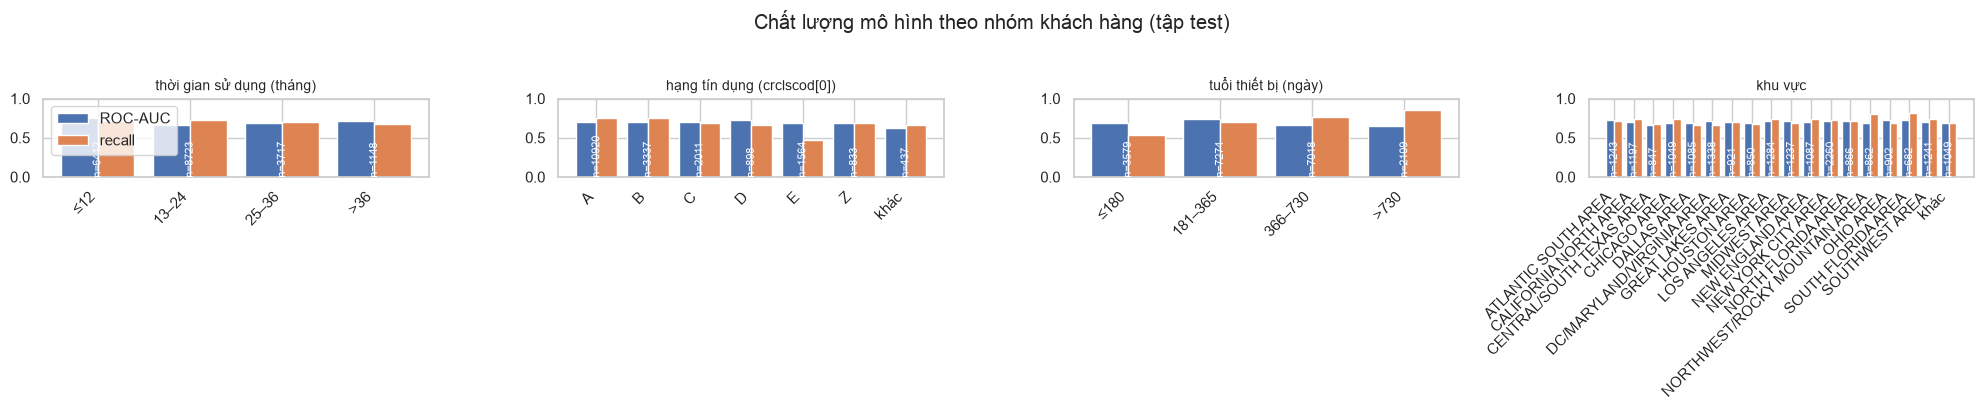

In [30]:
row = final.table[
    (final.table.model == best_name) & (final.table.threshold_rule == "oof_balanced")
].iloc[0]
groups = error_analysis(final.models[best_name], data, float(row.threshold))
save_table(pd.concat(groups, names=["cách chia"]).reset_index(level=0), "exp8_subgroups")
for name, table in groups.items():
    print(name)
    display(table)
reporting.plot_subgroups(groups, save="14_subgroups")
plt.show()

**Nhận xét 5.1 (phân tích lỗi, LightGBM ở ngưỡng 0,47).** Mô hình không đều giữa các nhóm khách hàng:
- **Thời gian sử dụng:** tốt nhất với khách mới ≤ 12 tháng (ROC-AUC 0,756), kém nhất ở 13–24 tháng (0,666) — nhóm đông nhất
  (8.723 khách) và churn cao nhất (51,7%): hành vi của nhóm "qua giai đoạn đầu" khó phân biệt hơn.
- **Tuổi thiết bị:** máy trên 2 năm churn cao nhất (58,6%) nhưng ROC-AUC thấp nhất (0,653) — mô hình biết nhóm này rủi ro (recall
  0,85) nhưng khó tách ai trong nhóm sẽ rời đi; máy 6–12 tháng phân biệt tốt nhất (0,742). Máy ≤ 6 tháng có recall thấp (0,53).
- **Hạng tín dụng:** hạng E có recall thấp nhất (0,47) và churn thấp (40,7%); nhóm hạng hiếm ("khác") có ROC-AUC thấp nhất (0,623).
- **Khu vực:** ROC-AUC dao động hẹp 0,667–0,731 ⇒ không khu vực nào bị bỏ sót nghiêm trọng.
⇒ Hướng cải thiện: đặc trưng riêng cho giai đoạn 13–24 tháng và cho khách có thiết bị cũ (vd. lịch sử nâng cấp máy).

## 6. Lưu đặc trưng đã trích xuất
Vector đặc trưng sau tiền xử lý (bộ tiền xử lý **fit trên train**) được lưu ra `features/<tên>/` dạng `.npy`
(`X_train`, `X_test`, `y_train`, `y_test`) kèm `meta.json` (cấu hình + tên đặc trưng).

In [31]:
for name, path in export_stage(BEST, data).items():
    print(f"{name:12s} -> {path}")

best_linear  -> /Users/kunne/Downloads/ML/features/best_linear
best_tree    -> /Users/kunne/Downloads/ML/features/best_tree
pca95        -> /Users/kunne/Downloads/ML/features/pca95


In [32]:
# Kiểm tra: nạp lại đặc trưng từ .npy và huấn luyện trực tiếp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

xa, xb, ya, yb = load_features("best_linear")
clf = LogisticRegression(max_iter=2000, class_weight="balanced").fit(xa, ya)
print(
    f"features/best_linear: X_train {xa.shape} -> ROC-AUC test = {roc_auc_score(yb, clf.predict_proba(xb)[:, 1]):.4f}"
)

features/best_linear: X_train (80000, 234) -> ROC-AUC test = 0.6509


## 7. Mở rộng: Deep Learning (MLP) so với pipeline truyền thống
Mạng nơ-ron nhiều tầng (MLP) — mô hình học sâu cho dữ liệu bảng — dùng cùng bộ tiền xử lý (StandardScaler), hai họ:
- **MLP sklearn** (`MLPClassifier`, Adam, early stopping);
- **MLP PyTorch** (`modules/modeling/torch_mlp.py`): [Linear → BatchNorm → ReLU → Dropout] × n, AdamW + BCE, dừng sớm theo
  loss validation, khôi phục trọng số tốt nhất; bọc thành estimator sklearn nên dùng chung pipeline, CV và chọn ngưỡng OOF.

Các kiến trúc trong `configs/default.yaml` được so sánh bằng CV; MLP tốt nhất của **mỗi họ** được đánh giá trên test như mục 5.

2026-11-25 10:30:27,207 INFO     modules.evaluation.experiment: [MLP sklearn (64,) alpha=0.001           ] CV ROC-AUC=0.6365 F1=0.5844 (4s)


2026-11-25 10:30:32,082 INFO     modules.evaluation.experiment: [MLP sklearn (128, 64) alpha=0.001       ] CV ROC-AUC=0.6299 F1=0.5992 (5s)


2026-11-25 10:30:37,401 INFO     modules.evaluation.experiment: [MLP sklearn (128, 64) alpha=0.01        ] CV ROC-AUC=0.6275 F1=0.5785 (5s)


2026-11-25 10:30:45,259 INFO     modules.evaluation.experiment: [MLP sklearn (256, 128, 64) alpha=0.01   ] CV ROC-AUC=0.6324 F1=0.6146 (8s)


2026-11-25 10:30:53,672 INFO     modules.evaluation.experiment: [MLP PyTorch (128, 64) dropout=0.2       ] CV ROC-AUC=0.6423 F1=0.5806 (8s)


2026-11-25 10:30:58,075 INFO     modules.evaluation.experiment: [MLP PyTorch (256, 128) dropout=0.3      ] CV ROC-AUC=0.6423 F1=0.5852 (4s)


,experiment,model_params,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_pr_auc
0,"MLP PyTorch (128, 64) dropout=0.2","{'hidden_layer_sizes': (128, 64), 'dropout': 0.2}",0.5997,0.6040,0.5590,0.5806,0.6423,0.6301
1,"MLP PyTorch (256, 128) dropout=0.3","{'hidden_layer_sizes': (256, 128), 'dropout': ...",0.6033,0.6074,0.5663,0.5852,0.6423,0.6307
2,"MLP sklearn (64,) alpha=0.001","{'hidden_layer_sizes': (64,), 'alpha': 0.001}",0.5973,0.5982,0.5714,0.5844,0.6365,0.6194
3,"MLP sklearn (256, 128, 64) alpha=0.01","{'hidden_layer_sizes': (256, 128, 64), 'alpha'...",0.5960,0.5833,0.6497,0.6146,0.6324,0.6193
4,"MLP sklearn (128, 64) alpha=0.001","{'hidden_layer_sizes': (128, 64), 'alpha': 0.001}",0.5925,0.5849,0.6164,0.5992,0.6299,0.6171
5,"MLP sklearn (128, 64) alpha=0.01","{'hidden_layer_sizes': (128, 64), 'alpha': 0.01}",0.5875,0.5858,0.5724,0.5785,0.6275,0.6160


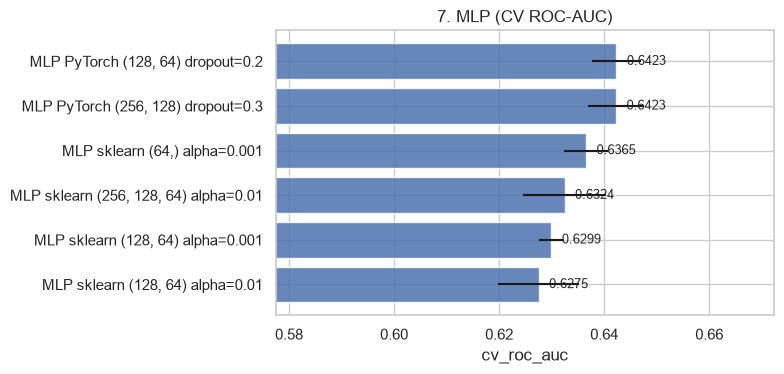

,model,threshold_rule,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
12,LightGBM (mặc định),default,0.50,0.6448,0.6381,0.6542,0.6460,0.7049,0.6973
9,Gradient Boosting (Hist) (tuned),default,0.50,0.6417,0.6353,0.6502,0.6427,0.7008,0.6924
6,Random Forest (tuned),default,0.50,0.6278,0.6185,0.6499,0.6338,0.6858,0.6774
18,MLP PyTorch (best),default,0.50,0.6206,0.6210,0.6017,0.6112,0.6691,0.6579
15,MLP sklearn (best),default,0.50,0.6118,0.6143,0.5820,0.5977,0.6581,0.6485
3,Logistic Regression (tuned),default,0.50,0.6096,0.6079,0.5979,0.6028,0.6507,0.6380
0,Baseline (Dummy),default,0.50,0.5044,0.0000,0.0000,0.0000,0.5000,0.4956
13,LightGBM (mặc định),oof_balanced,0.47,0.6438,0.6218,0.7180,0.6665,0.7049,0.6973
10,Gradient Boosting (Hist) (tuned),oof_balanced,0.49,0.6415,0.6285,0.6765,0.6516,0.7008,0.6924
7,Random Forest (tuned),oof_balanced,0.51,0.6280,0.6273,0.6143,0.6207,0.6858,0.6774


In [33]:
mlp_table, mlp_final = mlp_stage(BEST, data, S)
save_table(mlp_table, "exp7_mlp")
show(mlp_table, ["model_params"], "7. MLP (CV ROC-AUC)")
compare = pd.concat([final.table, mlp_final.table], ignore_index=True)
save_table(compare, "final_test_results")
display(compare.sort_values(["threshold_rule", "roc_auc"], ascending=[True, False]))

**Nhận xét 7 (học sâu vs truyền thống).**
- **MLP PyTorch** (BatchNorm + dropout + dừng sớm) tốt hơn **MLP sklearn** cả trên CV (0,642 so với 0,637) và test (ROC-AUC
  0,669 so với 0,658): BatchNorm và dropout giúp ổn định khi đặc trưng lệch và đa cộng tuyến.
- Trên CV (mẫu con 30k) MLP PyTorch chỉ ngang Logistic Regression (0,642 so với 0,643); trên test, khi học từ đủ 80k dòng, cả hai
  MLP **hơn Logistic Regression** (0,669 / 0,658 so với 0,651) ⇒ mạng nơ-ron cần nhiều dữ liệu hơn để khai thác quan hệ phi tuyến.
- Cả hai MLP **thua LightGBM (0,705), Gradient Boosting (0,701) và Random Forest (0,686)**. Phù hợp với nhận định phổ biến: trên
  dữ liệu bảng cỡ vừa, nhiều biến lệch/đa cộng tuyến, mô hình cây tăng cường vẫn mạnh hơn mạng nơ-ron; mạng nơ-ron còn tốn công
  chọn kiến trúc và nhạy với scaling hơn.

## 8. Kết luận

In [34]:
best_rows = compare[compare.threshold_rule.isin(["default", "oof_balanced"])].sort_values(
    ["threshold_rule", "roc_auc"], ascending=[True, False]
)
print(
    "Kết quả trên tập test: ngưỡng 0.5 và ngưỡng tối đa balanced accuracy chọn trên train (out-of-fold):"
)
display(best_rows.reset_index(drop=True))
print(f"\nCấu hình tiền xử lý cuối cùng: {BEST}")
print(f"Tổng thời gian chạy notebook: {(time.time() - NOTEBOOK_T0) / 60:.1f} phút")

Kết quả trên tập test: ngưỡng 0.5 và ngưỡng tối đa balanced accuracy chọn trên train (out-of-fold):


,model,threshold_rule,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
0,LightGBM (mặc định),default,0.50,0.6448,0.6381,0.6542,0.6460,0.7049,0.6973
1,Gradient Boosting (Hist) (tuned),default,0.50,0.6417,0.6353,0.6502,0.6427,0.7008,0.6924
2,Random Forest (tuned),default,0.50,0.6278,0.6185,0.6499,0.6338,0.6858,0.6774
3,MLP PyTorch (best),default,0.50,0.6206,0.6210,0.6017,0.6112,0.6691,0.6579
4,MLP sklearn (best),default,0.50,0.6118,0.6143,0.5820,0.5977,0.6581,0.6485
5,Logistic Regression (tuned),default,0.50,0.6096,0.6079,0.5979,0.6028,0.6507,0.6380
6,Baseline (Dummy),default,0.50,0.5044,0.0000,0.0000,0.0000,0.5000,0.4956
7,LightGBM (mặc định),oof_balanced,0.47,0.6438,0.6218,0.7180,0.6665,0.7049,0.6973
8,Gradient Boosting (Hist) (tuned),oof_balanced,0.49,0.6415,0.6285,0.6765,0.6516,0.7008,0.6924
9,Random Forest (tuned),oof_balanced,0.51,0.6280,0.6273,0.6143,0.6207,0.6858,0.6774



Cấu hình tiền xử lý cuối cùng: PipelineConfig(name='best', treat_hidden_missing=True, num_imputer='median', cat_imputer='most_frequent', add_missing_indicator=True, cat_encoder='onehot', high_card_encoder='frequency', log_transform=True, scaler='standard', minmax_range=(0.0, 1.0), feature_selection=None, selection_k=40, selection_c=0.05, pca_variance=None, model='logreg', model_params={}, class_weight='balanced')
Tổng thời gian chạy notebook: 17.6 phút


**Kết luận.**
1. Pipeline truyền thống cấu hình được (imputation → encoding → log/scaling → chọn đặc trưng / PCA → mô hình) được đánh giá có
   hệ thống bằng CV trên train; mỗi bước chọn theo quy tắc một sai số chuẩn; tập test chỉ dùng một lần; các kết luận chính được
   **kiểm định thống kê** (t-test hiệu chỉnh Nadeau–Bengio).
2. Bước tiền xử lý **có tác động thật (đã kiểm định)**: cờ giá trị thiếu và biến đổi log trước khi scale. Encoding không tạo khác
   biệt; PCA và lọc đặc trưng theo ANOVA F làm giảm chất lượng; L1 bỏ được ~1/3 số đặc trưng gần như không mất gì.
3. **Mô hình cây tăng cường** quyết định độ chính xác: LightGBM (chọn theo CV) đạt **ROC-AUC 0,705, accuracy 64,5%** trên test,
   so với mốc Dummy 0,5 / 50,4%; hơn Random Forest và Logistic Regression có ý nghĩa thống kê, và hơn cả hai MLP (mở rộng học sâu).
4. Ngưỡng phân loại chọn theo balanced accuracy (≈ 0,5 với dữ liệu cân bằng). Tối đa F1 không phù hợp với dữ liệu 50/50: nó đẩy
   mô hình về gần "đoán churn cho tất cả" (F1 của chiến lược tầm thường này đã là 0,663).
5. Phân tích lỗi: mô hình yếu nhất ở khách 13–24 tháng và khách có thiết bị trên 2 năm — gợi ý hướng bổ sung đặc trưng.
6. Giới hạn: tín hiệu trong dữ liệu yếu (|r| ≤ 0,11), dữ liệu từ đầu những năm 2000; thí nghiệm so sánh chạy trên mẫu con 30k để
   vừa thời gian Colab; tham số LightGBM không được tinh chỉnh trong notebook.